# P3 · Boiling point: one-shot ten-step workflow from a VIBE-structured prompt

A completed, executed demonstration of the ten-step workflow from [01 · Ten steps in prompts](../../../01_Ten_Steps_in_Prompts.ipynb), generated from the one-shot prompt in [one_shot_prompt_p3.txt](../prompts/P3_one_shot_prompt.txt). The task is SMILES to reported boiling point in kelvin. Read it top to bottom: each step shows what we asked, what we decided and why, and the real outputs.

<h1 style="color:#1D4E89;">Step 0: Conditioning the Coding Assistant</h1>

It helps to start by giving a coding assistant context for the full project. This makes later prompts easier and usually leads to more consistent code.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


<h3 style="color:#B05E27;">What we asked / what we decided</h3>


**What we asked.** The one-shot prompt (VIBE structure: Context → Role → Ask → Format → Tests) asked for the whole workflow in one request: plan first, build from the smallest working piece, explain every decision, keep the test set sealed until the model is frozen, then verify and refine.

**Condensed plan (Plan-and-Solve), written before any code:**

1. **Data:** use exactly one source. The preferred NIST acquisition is absent in this checkout, so use the packaged `data/CompoundData.parquet`; record its SHA-256 and confirm kelvin from provenance, not from the value range.
2. **Cleaning and identity:** parse with RDKit, reject missing/unparseable/multi-component/charged entries, strip stereo and isotope labels to form one canonical identity, merge agreeing repeats by median, exclude conflicting repeats; save a row-level audit.
3. **Split:** 80/10/10 random split of *unique molecules* (seed 42), frozen and saved before any target-informed plots.
4. **Features (SMILES only):** about 35 interpretable descriptors grouped by boiling-point mechanism, plus 1024-bit Morgan count fingerprints. All learned preprocessing lives inside pipelines fit on training rows.
5. **Baseline then candidates:** training-median baseline; ridge (interpretable linear reference), RBF support-vector regression (smooth kernel), histogram gradient boosting (nonlinear trees with a validation-stopped training history).
6. **Experiments:** model families, a feature-set comparison, an H-bond ablation and a small settings search, tracked in numbered folders.
7. **Creative enhancement:** a physics-motivated linear prior plus learned residual, and a nearest-neighbour applicability-domain score; success criteria fixed in advance.
8. **Analysis and self-consistency:** validation ranking, subgroup errors, chemical failures, bootstrap and cross-validation checks of the two key conclusions.
9. **Optimization:** one focused change motivated by Step 8, then freeze the full pipeline.
10. **Test once, then deploy:** test metrics versus baseline, a saved `predict_boiling_point` pipeline verified in a fresh Python process, edge-case checks.

**Main risks and guards.** *Leakage* → molecule-disjoint splits, train-only preprocessing, a test lock with timestamps. *Duplicate molecules* → identity decided before splitting. *Unit or pressure errors* → provenance check, and we call the target "reported BP", not "normal BP". *Runtime* → small, bounded grids; the whole notebook is timed against a 15-minute budget.

<h1 style="color:#1D4E89;">Step 1: Set Goal</h1>


1. **Intention:** predict the reported boiling point (BP, kelvin) of a small organic molecule from its SMILES string.
2. **Approach:** supervised regression on the prepared NIST-derived data in this module, with SMILES-derived features only.
3. **Success:** we care about typical error on unseen molecules, so **test MAE (K)** is the metric. Success, fixed before any modeling, means test MAE ≤ 20 K **and** at least 50% lower than the training-median baseline. We also want honest warnings when a molecule is unlike the training data.
4. **Together:** "Predict reported BP in kelvin from SMILES with test MAE ≤ 20 K and at least half the baseline error, and flag unfamiliar molecules."

<h1 style="color:#1D4E89;">Step 2: Define Inputs and Outputs</h1>


**Input:** one SMILES string (or a list). Every model feature is recomputed from it; stored columns such as `MW`, `CAS` and `mol3D` are never model inputs.

**Output:** predicted reported BP in K (and °C), a status (`ok` / `invalid` / `unsupported`), an applicability score and flag, and the nearest training molecule.

<h1 style="color:#1D4E89;">Step 3: Collect Data</h1>

This is already done. We use the prepared dataset distributed with the workshop; acquisition is not rerun.

<h2 style="color:#1D4E89;">Step 4: Examine Data</h2>


Inspect the schema and deterministic validity/identity problems first. Reserve reproducible molecule-disjoint training, validation, and test assignments before target-informed exploration; use training data for plots and investigations that will guide cleaning or modeling.

<h3 style="color:#B05E27;">What we asked / what we decided</h3>

We asked for one editable configuration cell, then a shared SMILES toolkit used by both training and inference, so that the saved model can never featurize molecules differently from the notebook.

### Editable run configuration

Code Summary: Sets every path, seed, split fraction, tolerance and threshold used below, finds the repository from either the root or the notebook folder, and chooses an output folder that is never shared with another run.


In [1]:
from pathlib import Path
import datetime as dt
import json
import shutil
import time

RUN_START = time.perf_counter()
RUN_STARTED_UTC = dt.datetime.now(dt.timezone.utc).isoformat(timespec='seconds')


def find_repo_root(start=None):
    """Walk up from the working directory to the workshop repository root."""
    start = Path.cwd() if start is None else Path(start)
    for path in [start, *start.parents]:
        if (path / 'pyproject.toml').is_file() and (path / '01_boiling_point').is_dir():
            return path
    raise FileNotFoundError('Start Jupyter inside the workshop repository.')


REPO = find_repo_root()
MODULE_DIR = REPO / '01_boiling_point'
NOTEBOOK_REL = '01_boiling_point/prompt_test/03_P3_BP_One_Shot_Workflow.ipynb'

# ---- editable settings -------------------------------------------------
PREFERRED_DATA = MODULE_DIR / 'outputs/nist_acquisition/NIST_BP_SMILES.parquet'
FALLBACK_DATA = MODULE_DIR / 'data/CompoundData.parquet'
OUTPUT_NAME = 'bp_one_shot_3'
SEED = 42
SPLIT_FRACTIONS = {'train': 0.8, 'validation': 0.1, 'test': 0.1}
REPEAT_TOLERANCE_K = 10.0        # repeats of one structure must agree within this
MW_TOLERANCE_G_MOL = 0.5         # stored vs SMILES molecular weight (audit only)
PLAUSIBLE_BP_K = (1.0, 2000.0)   # physically possible range; not a unit test
LOW_BP_REVIEW_K = 150.0          # flag (but keep) very volatile entries
MORGAN_RADIUS, MORGAN_COUNT_BITS, SIMILARITY_BITS = 2, 1024, 2048
AD_THRESHOLDS = {'in-domain': 0.5, 'borderline': 0.3}  # nearest-neighbour Tanimoto
SIZE_MARGIN = 1.25               # supported size = margin x largest training molecule
SUCCESS_MAE_K, SUCCESS_BASELINE_REDUCTION = 20.0, 0.5
MEANINGFUL_GAIN_K = 1.0          # smaller validation gains do not justify complexity
N_BOOTSTRAP, CV_FOLDS = 1000, 5
RUNTIME_BUDGET_MIN = 15
# -------------------------------------------------------------------------


def choose_output_dir(base, name, owner):
    """Reuse this notebook's own folder; use a versioned name if another run owns it."""
    for version in range(1, 100):
        candidate = base / (name if version == 1 else f'{name}_v{version}')
        marker = candidate / 'run_owner.json'
        if not candidate.exists() or not any(candidate.iterdir()):
            candidate.mkdir(parents=True, exist_ok=True)
            marker.write_text(json.dumps({'notebook': owner}) + '\n')
            return candidate
        if marker.exists() and json.loads(marker.read_text()).get('notebook') == owner:
            return candidate
    raise RuntimeError('No free output folder name found.')


OUT_DIR = choose_output_dir(MODULE_DIR / 'outputs', OUTPUT_NAME, NOTEBOOK_REL)
FIG_DIR, EXP_DIR = OUT_DIR / 'figures', OUT_DIR / 'experiments'
for stale in (FIG_DIR, EXP_DIR):  # a rerun replaces this notebook's own results
    shutil.rmtree(stale, ignore_errors=True)
    stale.mkdir(parents=True)
INFERENCE_MODULE = OUT_DIR / 'bp_inference.py'
STAGES = []  # names of completed stages, checked by the Verification cell
print(f'Repository: {REPO}')
print(f'Outputs:    {OUT_DIR.relative_to(REPO)}')
print(f'Started:    {RUN_STARTED_UTC}')

Repository: /home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop
Outputs:    01_boiling_point/outputs/bp_one_shot_3
Started:    2026-11-03T22:15:37+00:00


### Shared SMILES toolkit for training and inference

Code Summary: Writes the small module that parses and standardizes SMILES, computes descriptors and fingerprints, scores similarity and wraps the final predictor. The notebook imports this same file, so training and saved-model inference cannot drift apart.


In [2]:
%%writefile {INFERENCE_MODULE}
"""SMILES processing, features, and inference for the P3 boiling-point workflow.

Written by 01_boiling_point/prompt_test/03_P3_BP_One_Shot_Workflow.ipynb.
Training and inference both import this file, so they apply identical transformations.
Edit the notebook cell that writes it, not this generated copy.
"""
from __future__ import annotations

from functools import lru_cache

import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Crippen, Descriptors, Fragments, rdFingerprintGenerator, rdMolDescriptors
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.linear_model import LinearRegression

RDLogger.DisableLog("rdApp.*")


def standardize_smiles(smiles):
    """Parse one SMILES and return (mol, canonical_smiles, status, note).

    status is 'ok', 'invalid' (cannot be read) or 'unsupported' (readable but not a
    single neutral molecule). Stereo and isotope labels are removed, so stereoisomers
    and isotopologues share one identity, matching how the training labels are stored.
    """
    if not isinstance(smiles, str) or not smiles.strip():
        return None, None, "invalid", "empty or missing SMILES"
    mol = Chem.MolFromSmiles(smiles.strip())
    if mol is None:
        return None, None, "invalid", "RDKit could not parse the SMILES"
    if len(Chem.GetMolFrags(mol)) > 1:
        return None, Chem.MolToSmiles(mol), "unsupported", "multi-component entry (salt or mixture)"
    if Chem.GetFormalCharge(mol) != 0:
        return None, Chem.MolToSmiles(mol), "unsupported", "net charge (ion)"
    notes = []
    if any(atom.GetIsotope() for atom in mol.GetAtoms()):
        for atom in mol.GetAtoms():
            atom.SetIsotope(0)
        notes.append("isotope labels removed")
    if Chem.MolToSmiles(mol) != Chem.MolToSmiles(mol, isomericSmiles=False):
        notes.append("stereochemistry removed")
    canonical = Chem.MolToSmiles(mol, isomericSmiles=False)
    return Chem.MolFromSmiles(canonical), canonical, "ok", "; ".join(notes)


def _branched_carbons(mol):
    """Carbons bonded to three or more heavy atoms (branch points)."""
    return sum(a.GetSymbol() == "C" and a.GetDegree() >= 3 for a in mol.GetAtoms())


def _quaternary_carbons(mol):
    return sum(a.GetSymbol() == "C" and a.GetDegree() == 4 for a in mol.GetAtoms())


def _symmetry_fraction(mol):
    """Unique atom environments / heavy atoms; lower values mean a more symmetric molecule."""
    ranks = list(Chem.CanonicalRankAtoms(mol, breakTies=False))
    return len(set(ranks)) / len(ranks)


def _element_counter(symbol):
    return lambda mol: sum(a.GetSymbol() == symbol for a in mol.GetAtoms())


# Each descriptor is a chemical hypothesis about boiling point, grouped by mechanism.
DESCRIPTOR_GROUPS = {
    "size and polarizability": {
        "MolWt": Descriptors.MolWt,
        "HeavyAtomCount": Descriptors.HeavyAtomCount,
        "MolMR": Crippen.MolMR,
        "LabuteASA": rdMolDescriptors.CalcLabuteASA,
    },
    "shape and branching": {
        "Kappa1": rdMolDescriptors.CalcKappa1,
        "Kappa2": rdMolDescriptors.CalcKappa2,
        "Kappa3": rdMolDescriptors.CalcKappa3,
        "Chi1v": rdMolDescriptors.CalcChi1v,
        "NumRotatableBonds": rdMolDescriptors.CalcNumRotatableBonds,
        "BranchedCarbons": _branched_carbons,
        "QuaternaryCarbons": _quaternary_carbons,
        "SymmetryFraction": _symmetry_fraction,
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3,
        "RingCount": rdMolDescriptors.CalcNumRings,
        "NumAromaticRings": rdMolDescriptors.CalcNumAromaticRings,
    },
    "polarity and hydrogen bonding": {
        "TPSA": rdMolDescriptors.CalcTPSA,
        "MolLogP": Crippen.MolLogP,
        "NumHDonors": rdMolDescriptors.CalcNumHBD,
        "NumHAcceptors": rdMolDescriptors.CalcNumHBA,
        "fr_Al_OH": Fragments.fr_Al_OH,
        "fr_Ar_OH": Fragments.fr_Ar_OH,
        "fr_COO": Fragments.fr_COO,
        "fr_NH2": Fragments.fr_NH2,
        "fr_NH1": Fragments.fr_NH1,
    },
    "heteroatoms and functional groups": {
        "count_N": _element_counter("N"),
        "count_O": _element_counter("O"),
        "count_S": _element_counter("S"),
        "count_Cl": _element_counter("Cl"),
        "fr_C_O": Fragments.fr_C_O,
        "fr_ester": Fragments.fr_ester,
        "fr_ether": Fragments.fr_ether,
        "fr_nitro": Fragments.fr_nitro,
        "fr_nitrile": Fragments.fr_nitrile,
        "fr_amide": Fragments.fr_amide,
    },
}
DESCRIPTORS = {name: f for group in DESCRIPTOR_GROUPS.values() for name, f in group.items()}
HBOND_DESCRIPTORS = ["NumHDonors", "NumHAcceptors", "fr_Al_OH", "fr_Ar_OH", "fr_COO", "fr_NH2", "fr_NH1"]


def descriptor_frame(mols):
    """Interpretable RDKit descriptors; non-finite values become NaN for train-fitted imputation."""
    rows = [[float(f(m)) for f in DESCRIPTORS.values()] for m in mols]
    return pd.DataFrame(rows, columns=list(DESCRIPTORS)).replace([np.inf, -np.inf], np.nan)


@lru_cache(maxsize=None)
def _morgan_generator(radius, n_bits):
    return rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)


def morgan_count_frame(mols, radius, n_bits):
    """Hashed Morgan count fingerprint: how often each local substructure occurs."""
    gen = _morgan_generator(radius, n_bits)
    counts = np.vstack([gen.GetCountFingerprintAsNumPy(m) for m in mols]).astype(float)
    return pd.DataFrame(counts, columns=[f"morgan_r{radius}_{i:04d}" for i in range(n_bits)])


def featurize(mols, feature_columns, radius, n_bits):
    """Build the model matrix, in the saved column order, from RDKit molecules only."""
    parts = []
    if any(c in DESCRIPTORS for c in feature_columns):
        parts.append(descriptor_frame(mols))
    if any(c.startswith("morgan_") for c in feature_columns):
        parts.append(morgan_count_frame(mols, radius, n_bits))
    return pd.concat(parts, axis=1)[list(feature_columns)]


def similarity_fingerprints(mols, radius, n_bits):
    """Morgan bit vectors used only for Tanimoto similarity (applicability domain)."""
    gen = _morgan_generator(radius, n_bits)
    return [gen.GetFingerprint(m) for m in mols]


def nearest_neighbors(query_fps, reference_fps):
    """Return (highest Tanimoto similarity, index of that reference) for each query."""
    best_sim, best_idx = [], []
    for fp in query_fps:
        sims = np.asarray(DataStructs.BulkTanimotoSimilarity(fp, reference_fps))
        i = int(sims.argmax())
        best_sim.append(float(sims[i]))
        best_idx.append(i)
    return np.array(best_sim), np.array(best_idx, dtype=int)


class PriorResidualRegressor(RegressorMixin, BaseEstimator):
    """A linear prior on a few interpretable columns plus a learned model of what it misses."""

    def __init__(self, prior_columns=(0,), residual_model=None):
        self.prior_columns = prior_columns
        self.residual_model = residual_model

    def _prior_inputs(self, X):
        Z = np.asarray(X, dtype=float)[:, list(self.prior_columns)]
        return np.where(np.isnan(Z), self.prior_medians_, Z)

    def fit(self, X, y):
        Z = np.asarray(X, dtype=float)[:, list(self.prior_columns)]
        self.prior_medians_ = np.nanmedian(Z, axis=0)  # training rows only
        self.prior_ = LinearRegression().fit(self._prior_inputs(X), y)
        residual = np.asarray(y, dtype=float) - self.prior_.predict(self._prior_inputs(X))
        self.residual_model_ = clone(self.residual_model).fit(X, residual)
        return self

    def predict_prior(self, X):
        return self.prior_.predict(self._prior_inputs(X))

    def predict(self, X):
        return self.predict_prior(X) + self.residual_model_.predict(X)

    def staged_predict(self, X):
        base = self.predict_prior(X)
        for residual in self.residual_model_.staged_predict(X):
            yield base + residual


class BoilingPointPredictor:
    """Frozen SMILES -> boiling-point pipeline with input checks and applicability scores."""

    def __init__(self, model, feature_columns, train_smiles, train_bp_k, allowed_elements,
                 max_heavy_atoms, ad_thresholds, radius, count_bits, similarity_bits, metadata=None):
        self.model = model
        self.feature_columns = list(feature_columns)
        self.train_smiles = list(train_smiles)
        self.train_bp_k = np.asarray(train_bp_k, dtype=float)
        self.allowed_elements = sorted(allowed_elements)
        self.max_heavy_atoms = int(max_heavy_atoms)
        self.ad_thresholds = dict(ad_thresholds)
        self.radius, self.count_bits, self.similarity_bits = radius, count_bits, similarity_bits
        self.metadata = dict(metadata or {})
        self._train_fps = None

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_train_fps"] = None  # rebuilt from SMILES after loading; keeps the file small
        return state

    def _reference_fps(self):
        if self._train_fps is None:
            mols = [Chem.MolFromSmiles(s) for s in self.train_smiles]
            self._train_fps = similarity_fingerprints(mols, self.radius, self.similarity_bits)
        return self._train_fps

    def support_problem(self, mol):
        """Return why a parsed molecule is outside the supported chemistry, or ''."""
        extra = sorted({a.GetSymbol() for a in mol.GetAtoms()} - set(self.allowed_elements))
        if extra:
            return f"element(s) never seen in training: {', '.join(extra)}"
        if mol.GetNumHeavyAtoms() > self.max_heavy_atoms:
            return f"{mol.GetNumHeavyAtoms()} heavy atoms exceeds the supported maximum of {self.max_heavy_atoms}"
        return ""

    def applicability(self, similarity):
        if similarity >= self.ad_thresholds["in-domain"]:
            return "in-domain"
        if similarity >= self.ad_thresholds["borderline"]:
            return "borderline"
        return "out-of-domain"

    def predict(self, smiles):
        """Predict for one SMILES or a list; one output row per input, in input order."""
        items = [smiles] if isinstance(smiles, str) else list(smiles)
        train_set = set(self.train_smiles)
        records, ok_mols, ok_rows = [], [], []
        for i, item in enumerate(items):
            mol, canonical, status, note = standardize_smiles(item)
            if status == "ok":
                problem = self.support_problem(mol)
                if problem:
                    status, note = "unsupported", problem
            records.append({
                "input_smiles": item, "canonical_smiles": canonical, "status": status, "note": note,
                "predicted_bp_K": np.nan, "predicted_bp_C": np.nan, "max_tanimoto_to_train": np.nan,
                "applicability": "not scored", "nearest_train_smiles": None, "nearest_train_bp_K": np.nan,
                "in_training_set": bool(status == "ok" and canonical in train_set),
            })
            if status == "ok":
                ok_mols.append(mol)
                ok_rows.append(i)
        if ok_mols:
            X = featurize(ok_mols, self.feature_columns, self.radius, self.count_bits).to_numpy(float)
            predictions = self.model.predict(X)
            sims, nearest = nearest_neighbors(
                similarity_fingerprints(ok_mols, self.radius, self.similarity_bits), self._reference_fps())
            for row, pred, sim, j in zip(ok_rows, predictions, sims, nearest):
                records[row].update(
                    predicted_bp_K=float(pred), predicted_bp_C=float(pred) - 273.15,
                    max_tanimoto_to_train=float(sim), applicability=self.applicability(sim),
                    nearest_train_smiles=self.train_smiles[j], nearest_train_bp_K=float(self.train_bp_k[j]))
        return pd.DataFrame(records)

Overwriting /home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/bp_inference.py


### Imports, plotting style and helpers

Code Summary: Imports the libraries and the toolkit written above, sets a readable plot style with a colorblind-safe palette, and defines small helpers for saving figures and computing metrics in kelvin.


In [3]:
import hashlib
import importlib
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdkit
import sklearn
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sys.path.insert(0, str(OUT_DIR))
bp_inference = importlib.reload(importlib.import_module('bp_inference'))
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 60)

COLORS = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100', 'gray': '#8a8984'}
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'font.size': 11, 'axes.titlesize': 13,
                     'axes.labelsize': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False})


def save_figure(fig, name):
    """Save a slide-ready PNG in the figures folder and show it inline."""
    path = FIG_DIR / f'{name}.png'
    fig.tight_layout()
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved {path.relative_to(REPO)}')
    return path


def regression_metrics(y_true, y_pred):
    """MAE, median absolute error and RMSE in kelvin, R-squared, and the sample count."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {'n': len(y_true), 'MAE_K': mean_absolute_error(y_true, y_pred),
            'MedAE_K': float(np.median(np.abs(y_true - y_pred))),
            'RMSE_K': float(np.sqrt(mean_squared_error(y_true, y_pred))), 'R2': r2_score(y_true, y_pred)}


def utc_now():
    return dt.datetime.now(dt.timezone.utc).isoformat(timespec='seconds')


print(f'RDKit {rdkit.__version__} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | NumPy {np.__version__}')

RDKit 2024.03.6 | scikit-learn 1.6.1 | pandas 2.2.3 | NumPy 2.0.0


<h3 style="color:#B05E27;">What we asked / what we decided</h3>

Load exactly one source, record its checksum, and establish units from documentation and known reference values rather than from the range of numbers.

### Select and load exactly one data source

Code Summary: Uses the preferred NIST acquisition if present, otherwise the packaged fallback, never both. Records the file checksum, prints the schema and previews the first rows without the long 3D-structure text.


In [4]:
def sha256_file(path, chunk=1 << 20):
    """Return the SHA-256 checksum of a file."""
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(chunk), b''):
            digest.update(block)
    return digest.hexdigest()


DATA_PATH = PREFERRED_DATA if PREFERRED_DATA.exists() else FALLBACK_DATA
DATA_REL = DATA_PATH.relative_to(REPO).as_posix()
DATA_SHA256 = sha256_file(DATA_PATH)
raw = pd.read_parquet(DATA_PATH)
print(f'Preferred NIST acquisition present: {PREFERRED_DATA.exists()}')
print(f'Selected source (only one): {DATA_REL}')
print(f'SHA-256: {DATA_SHA256}')
print(f'Rows x columns: {raw.shape}\n')
print(raw.dtypes.to_string())
display(raw.drop(columns=['mol3D'], errors='ignore').head())
STAGES.append('load')

Preferred NIST acquisition present: False
Selected source (only one): 01_boiling_point/data/CompoundData.parquet
SHA-256: 755b5ad95eef073ee7cda9d653976afe9c3e34703765de1e6572b551cb0884e1
Rows x columns: (3541, 5)

CAS        object
MW        float64
BP        float64
SMILES     object
mol3D      object


,CAS,MW,BP,SMILES
0,999-90-6,132.2240,405.0,CC(=O)SC(C)(C)C
1,99-98-9,136.1943,536.2,CN(C)C1=CC=C(C=C1)N
2,999-78-0,96.1702,356.0,CC#CC(C)(C)C
3,99-97-8,135.2062,484.2,CC1=CC=C(C=C1)N(C)C
4,99-94-5,136.1479,547.7,CC1=CC=C(C=C1)C(=O)O


### Establish boiling-point units from provenance

Code Summary: Checks three independent pieces of evidence: the module documentation, the NIST origin of the stored structures, and three permanent gases whose literature normal boiling points are well known. Their values in this file match kelvin, not Celsius.


In [5]:
readme_kelvin = 'kelvin' in (MODULE_DIR / 'README.md').read_text().lower()
nist_fraction = raw['mol3D'].fillna('').str.contains('NIST').mean() if 'mol3D' in raw else float('nan')
# Literature normal boiling points (K), used only to check units, never as data.
REFERENCE_GASES = {'N#N': ('nitrogen', 77.36), 'O=O': ('oxygen', 90.19), '[C-]#[O+]': ('carbon monoxide', 81.6)}
canon = raw['SMILES'].map(lambda s: bp_inference.standardize_smiles(s)[1])
rows = []
for smi, (name, lit_k) in REFERENCE_GASES.items():
    match = raw.loc[canon == bp_inference.standardize_smiles(smi)[1], 'BP']
    rows.append({'molecule': name, 'file BP': match.iloc[0] if len(match) else np.nan, 'literature (K)': lit_k,
                 'literature (degC)': round(lit_k - 273.15, 2)})
unit_check = pd.DataFrame(rows)
display(unit_check)
gas_match = bool((unit_check['file BP'] - unit_check['literature (K)']).abs().max() < 1.0)
BP_UNITS = 'K' if readme_kelvin and gas_match else None
print(f'Module README states kelvin: {readme_kelvin}')
print(f'Rows whose stored 3D block carries a NIST header: {nist_fraction:.1%}')
print(f'Reference gases agree with kelvin values within 1 K: {gas_match}')
assert BP_UNITS == 'K', 'Units could not be confirmed as kelvin; stop and investigate.'
print('Conclusion: BP is in kelvin. Pressure is not recorded per row, so we call it "reported BP".')

,molecule,file BP,literature (K),literature (degC)
0,nitrogen,77.34,77.36,-195.79
1,oxygen,90.20,90.19,-182.96
2,carbon monoxide,81.63,81.60,-191.55


Module README states kelvin: True
Rows whose stored 3D block carries a NIST header: 100.0%
Reference gases agree with kelvin values within 1 K: True
Conclusion: BP is in kelvin. Pressure is not recorded per row, so we call it "reported BP".


**Decision: units and pressure.** The README documents kelvin, the structures come from NIST, and N₂, O₂ and CO sit within 1 K of their literature normal boiling points in kelvin (in °C they would be about −196, −183 and −192). The range of values alone could not have told us this. The file does **not** record pressure, so we never claim normal-pressure boiling points.

<h3 style="color:#B05E27;">What we asked / what we decided</h3>

Audit every row with a reason before any modeling, and decide molecular identity before splitting.

**Decision: cleaning policy and molecular identity.**
Options: keep every row, drop anything odd, or apply a small set of documented rules.
Reasoning: (1) A model can only use what RDKit can read from one neutral molecule, so missing, unparseable, multi-component or net-charged SMILES are excluded. Charge-separated neutral groups such as nitro stay. (2) This file stores SMILES without stereochemistry or isotopes, so stereoisomers (and isotopically labelled compounds) collapse onto one structure; the canonical non-isomeric SMILES is therefore the identity. (3) The stored `MW` is an independent record of the substance that was measured; if it disagrees with the SMILES by more than 0.5 g/mol, the structure–label pairing is doubtful (for example a deuterated compound stored as its ordinary parent), so we exclude the row. `MW` is used *only* for this audit, never as a feature. (4) Repeats of one identity that agree within 10 K are probably independent reports, so we take the median; larger disagreements may be stereoisomers with genuinely different BPs or data errors, and the input cannot distinguish them, so the whole group is excluded and counted.
Choice: exclude invalid rows and conflicting groups; merge agreeing repeats; flag but keep very low BPs and radicals for inspection.
What the learner should notice: identity is decided before splitting, and every removal has a written reason.

### Row-level validity and identity audit

Code Summary: Standardizes every SMILES, applies the documented rules, then groups rows by canonical structure, merging agreeing repeats and excluding conflicts. Prints counts per action and representative flagged rows with reasons.


In [6]:
def audit_rows(frame):
    """Return one audit record per source row with an action and a reason."""
    records = []
    for row_id, row in frame.iterrows():
        bp = pd.to_numeric(pd.Series([row.get('BP')]), errors='coerce').iloc[0]
        mol, canonical, status, note = bp_inference.standardize_smiles(row.get('SMILES'))
        action, reason = 'keep', note
        if status != 'ok':
            action, reason = 'exclude', f'{status} SMILES: {note}'
        elif not np.isfinite(bp):
            action, reason = 'exclude', 'missing, non-numeric or non-finite BP'
        elif not PLAUSIBLE_BP_K[0] <= bp <= PLAUSIBLE_BP_K[1]:
            action, reason = 'exclude', 'BP outside the physically plausible range'
        elif 'MW' in frame and abs(row['MW'] - Descriptors.MolWt(mol)) > MW_TOLERANCE_G_MOL:
            action, reason = 'exclude', (f"stored MW {row['MW']:.2f} vs SMILES MW {Descriptors.MolWt(mol):.2f} g/mol: "
                                         'structure may not match the measured substance')
        elif Descriptors.NumRadicalElectrons(mol) > 0:
            reason = 'kept; review: radical (unpaired electrons)'
        elif bp < LOW_BP_REVIEW_K:
            reason = 'kept; review: very low BP (permanent gas?)'
        records.append({'row_id': row_id, 'CAS_audit_only': row.get('CAS'), 'original_smiles': row.get('SMILES'),
                        'canonical_smiles': canonical, 'BP_K': bp, 'action': action, 'reason': reason})
    return pd.DataFrame(records)


def resolve_identities(audit, tolerance):
    """Merge agreeing repeats by median; exclude identity groups whose reports disagree."""
    kept = audit['action'].eq('keep')
    stats = (audit[kept].groupby('canonical_smiles')['BP_K']
             .agg(n_reports='size', BP_K='median', bp_min='min', bp_max='max'))
    stats['bp_spread_K'] = stats['bp_max'] - stats['bp_min']
    conflict = stats.index[stats['bp_spread_K'] > tolerance]
    merged = stats.index[(stats['n_reports'] > 1) & (stats['bp_spread_K'] <= tolerance)]
    in_conflict = kept & audit['canonical_smiles'].isin(conflict)
    spread = audit['canonical_smiles'].map(stats['bp_spread_K'])
    audit.loc[in_conflict, 'action'] = 'exclude'
    audit.loc[in_conflict, 'reason'] = 'conflicting repeats: spread ' + spread[in_conflict].round(1).astype(str) + f' K > {tolerance:g} K'
    in_merge = kept & audit['canonical_smiles'].isin(merged)
    audit.loc[in_merge, 'action'] = 'merge (median)'
    clean = stats.drop(index=conflict)[['BP_K', 'n_reports', 'bp_spread_K']].reset_index()
    return audit, clean.sort_values('canonical_smiles', ignore_index=True)


audit = audit_rows(raw)
audit, clean = resolve_identities(audit, REPEAT_TOLERANCE_K)
print(f'Source rows: {len(raw)} -> eligible unique molecules: {len(clean)}\n')
print(audit['action'].value_counts().to_string(), '\n')
reason_summary = (audit[audit['reason'] != ''].assign(reason_type=lambda d: d['reason'].str.split(':').str[0])
                  .groupby(['action', 'reason_type']).size().rename('rows'))
print(reason_summary.to_string())
flagged = audit[audit['reason'] != ''].assign(reason_type=lambda d: d['reason'].str.split(':').str[0])
display(flagged.groupby('reason_type').head(2)[['CAS_audit_only', 'original_smiles', 'BP_K', 'action', 'reason']])
STAGES.append('audit')

Source rows: 3541 -> eligible unique molecules: 3185

action
keep              3113
exclude            265
merge (median)     163 

action   reason_type                               
exclude  conflicting repeats                            28
         invalid SMILES                                229
         stored MW 120.62 vs SMILES MW 332.41 g/mol      1
         stored MW 124.22 vs SMILES MW 175.19 g/mol      1
         stored MW 134.60 vs SMILES MW 262.26 g/mol      1
         stored MW 146.23 vs SMILES MW 333.43 g/mol      1
         stored MW 69.11 vs SMILES MW 85.11 g/mol        1
         stored MW 84.15 vs SMILES MW 78.11 g/mol        1
         stored MW 86.14 vs SMILES MW 88.15 g/mol        1
         stored MW 96.17 vs SMILES MW 292.33 g/mol       1
keep     kept; review                                    6


,CAS_audit_only,original_smiles,BP_K,action,reason
19,99363-14-1,None,410.10,exclude,invalid SMILES: empty or missing SMILES
20,99363-13-0,None,409.10,exclude,invalid SMILES: empty or missing SMILES
55,96-15-1,CCC(C)CN,368.70,exclude,conflicting repeats: spread 272.2 K > 10 K
307,822-86-6,C1CCC(C(C1)Cl)Cl,466.70,exclude,conflicting repeats: spread 13.4 K > 10 K
358,7782-44-7,O=O,90.20,keep,kept; review: very low BP (permanent gas?)
370,7727-37-9,N#N,77.34,keep,kept; review: very low BP (permanent gas?)
1016,5916-22-3,CC(C1CC2CCC1C2)NC(=O)C3=CC(=C(C(=C3)OC)OC)OC,482.15,exclude,stored MW 146.23 vs SMILES MW 333.43 g/mol: structure ma...
1086,5750-00-5,C1=CC=NC(=C1)C2=CSC(=N2)NC3=CC=C(C=C3)S(=O)(=O)N,371.00,exclude,stored MW 120.62 vs SMILES MW 332.41 g/mol: structure ma...
1107,5675-22-9,CC(=C)COC1=CC2=C(C=C1)C(=CC(=O)O2)C3=CC=CC=C3,366.23,exclude,stored MW 96.17 vs SMILES MW 292.33 g/mol: structure may...
1391,500026-39-1,CCOC1=CC=C(C=C1)C2=NOC(=N2)CCC(=O)O,405.70,exclude,stored MW 134.60 vs SMILES MW 262.26 g/mol: structure ma...


**Measured finding: audit.** Of 3541 source rows, 229 have no SMILES (they cannot be featurized), 8 have a stored molecular weight that disagrees with their SMILES, and 28 rows fall in identity groups whose reports disagree by more than 10 K. One example is benzene-d6 (CAS 1076-43-3): its isotope labels were lost when it was stored, so it appears as ordinary benzene, and the weight check excludes it. Another is 2-methylbutylamine (`CCC(C)CN`), stored once at 96.5 K and once at 368.7 K. Agreeing repeats (163 rows) are merged by median. No SMILES in this file carries stereochemistry, isotopes, multiple components or a net charge, so those rules had nothing to remove here, but the prediction function enforces them. **Result: 3185 unique, eligible molecules.**

<h3 style="color:#B05E27;">What we asked / what we decided</h3>

Freeze the molecule-disjoint split now, before looking at how the target relates to anything.

**Decision: split design.**
Options: random split of molecules, scaffold split, or cluster split.
Reasoning: (1) Most molecules here are small and many are acyclic, so Bemis–Murcko scaffolds would put hundreds of chain molecules into one empty-scaffold group and make the split very unbalanced. (2) A random split of *unique* molecules estimates error for new molecules drawn from the same chemical families as the training data, which matches how the workshop model is used. (3) Its weakness is optimism for unfamiliar chemistry; we address that with a nearest-neighbour similarity score and error-by-similarity analysis instead of a second split.
Choice: frozen 80/10/10 random split of unique canonical identities with seed 42, saved to disk and asserted disjoint.
What the learner should notice: the split is fixed once and never changed to improve a score.

### Reserve frozen molecule-disjoint splits

Code Summary: Assigns each unique molecule, not each row, to train, validation or test with a fixed seed, saves the assignments, and asserts that no identity appears in two splits and that the counts add up.


In [7]:
def assign_splits(identities, fractions, seed):
    """Randomly assign each unique molecule to exactly one split."""
    ids = np.sort(np.asarray(identities, dtype=object))
    order = np.random.default_rng(seed).permutation(len(ids))
    n_train = int(round(fractions['train'] * len(ids)))
    n_val = int(round(fractions['validation'] * len(ids)))
    labels = np.empty(len(ids), dtype=object)
    labels[order[:n_train]] = 'train'
    labels[order[n_train:n_train + n_val]] = 'validation'
    labels[order[n_train + n_val:]] = 'test'
    return pd.DataFrame({'canonical_smiles': ids, 'split': labels})


split_table = assign_splits(clean['canonical_smiles'], SPLIT_FRACTIONS, SEED)
clean = clean.merge(split_table, on='canonical_smiles', validate='one_to_one')
SPLIT_SETS = {s: set(clean.loc[clean['split'] == s, 'canonical_smiles']) for s in SPLIT_FRACTIONS}
assert not SPLIT_SETS['train'] & SPLIT_SETS['validation']
assert not SPLIT_SETS['train'] & SPLIT_SETS['test']
assert not SPLIT_SETS['validation'] & SPLIT_SETS['test']
assert sum(map(len, SPLIT_SETS.values())) == len(clean) == clean['canonical_smiles'].nunique()
split_table.to_csv(OUT_DIR / 'split_assignments.csv', index=False)
print(clean['split'].value_counts().reindex(list(SPLIT_FRACTIONS)).to_string())
print(f'Saved {(OUT_DIR / "split_assignments.csv").relative_to(REPO)}; identities are disjoint.')
STAGES.append('split')

split
train         2548
validation     318
test           319
Saved 01_boiling_point/outputs/bp_one_shot_3/split_assignments.csv; identities are disjoint.


### Training-only look at the target

Code Summary: Plots the training boiling-point distribution and boiling point against heavy-atom count, split by whether the molecule has a hydrogen-bond donor. Validation and test molecules are not shown.


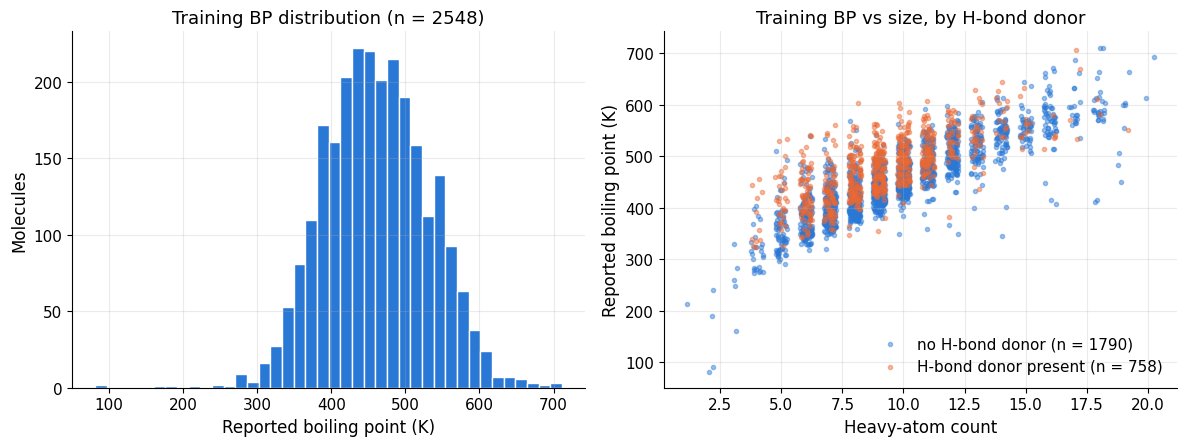

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig01_training_bp_distribution_and_size.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig01_training_bp_distribution_and_size.png')

In [8]:
train_view = clean[clean['split'] == 'train'].copy()
train_mols = [Chem.MolFromSmiles(s) for s in train_view['canonical_smiles']]
train_view['heavy_atoms'] = [m.GetNumHeavyAtoms() for m in train_mols]
train_view['has_hbd'] = [rdMolDescriptors.CalcNumHBD(m) > 0 for m in train_mols]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].hist(train_view['BP_K'], bins=40, color=COLORS['blue'], edgecolor='white')
axes[0].set(xlabel='Reported boiling point (K)', ylabel='Molecules',
            title=f'Training BP distribution (n = {len(train_view)})')
jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(train_view))
for flag, color, label in [(False, COLORS['blue'], 'no H-bond donor'), (True, COLORS['orange'], 'H-bond donor present')]:
    part = train_view['has_hbd'] == flag
    axes[1].scatter(train_view.loc[part, 'heavy_atoms'] + jitter[part.to_numpy()], train_view.loc[part, 'BP_K'],
                    s=9, alpha=0.45, color=color, label=f'{label} (n = {part.sum()})')
axes[1].set(xlabel='Heavy-atom count', ylabel='Reported boiling point (K)',
            title='Training BP vs size, by H-bond donor')
axes[1].legend(loc='lower right')
save_figure(fig, 'fig01_training_bp_distribution_and_size')

**Measured finding (training only).** Reported BPs cluster around 400–550 K, with a thin tail of permanent gases below 150 K. BP rises steeply with size and then flattens, which is curvature a straight line will miss. At a given size, molecules with a hydrogen-bond donor (orange) tend to sit above those without, which is consistent with the H-bonding hypothesis but does not yet test it.

### Inspect unusual training observations

Code Summary: Fits a simple training-only trend of boiling point against log heavy-atom count, then lists the lowest, highest and most off-trend training molecules for review. Nothing is removed here: unusual values are reasons to look, not proof of error.


In [9]:
trend = np.polyfit(np.log(train_view['heavy_atoms']), train_view['BP_K'], 1)
train_view['off_trend_K'] = train_view['BP_K'] - np.polyval(trend, np.log(train_view['heavy_atoms']))
cols = ['canonical_smiles', 'BP_K', 'heavy_atoms', 'n_reports', 'off_trend_K']
print(f'Training trend: BP = {trend[1]:.0f} K + {trend[0]:.0f} K x ln(heavy atoms)')
print('\nLowest reported BPs (training):')
display(train_view.nsmallest(5, 'BP_K')[cols].round(1))
print('Highest reported BPs (training):')
display(train_view.nlargest(3, 'BP_K')[cols].round(1))
print('Furthest below the size trend (possible reduced-pressure or mis-assigned labels):')
display(train_view.nsmallest(6, 'off_trend_K')[cols].round(1))
STAGES.append('examine')

Training trend: BP = 72 K + 176 K x ln(heavy atoms)

Lowest reported BPs (training):


,canonical_smiles,BP_K,heavy_atoms,n_reports,off_trend_K
3087,[C-]#[O+],81.6,2,1,-112.1
2956,O=O,90.2,2,1,-103.5
2986,O=[O+][O-],161.3,3,1,-103.6
0,C#C,189.0,2,1,-4.7
3069,S,212.9,1,1,140.9


Highest reported BPs (training):


,canonical_smiles,BP_K,heavy_atoms,n_reports,off_trend_K
3153,c1ccc2c(c1)c1ccccc1c1ccccc21,711.2,18,1,131.6
3160,c1ccc2cc3c(ccc4ccccc43)cc2c1,710.8,18,1,131.2
2543,Cc1ccc2nc(-c3ccc(N)cc3)sc2c1,707.2,17,1,137.6


Furthest below the size trend (possible reduced-pressure or mis-assigned labels):


,canonical_smiles,BP_K,heavy_atoms,n_reports,off_trend_K
1617,CCCCCCCCCCC(=O)OC,344.2,14,1,-191.3
1632,CCCCCCCCCCCCC(C)C(=O)OC,411.0,18,1,-168.6
1593,CCCCCCCCC#CCCCCCCCC,415.0,18,1,-164.6
771,CC(C)n1ccc2ccccc21,349.2,12,1,-159.2
1776,CCCCOC(=O)CCC(=O)OCCCC,408.0,16,1,-150.9
1639,CCCCCCCCCCCCCC(Cl)Cl,415.6,16,1,-143.3


**Decision: what to do with unusual training labels.**
Options: delete outliers, correct them, or keep them and report their effect.
Reasoning: (1) Some flagged values are real: CO, O₂ and ozone are genuinely volatile, and H₂S (`S`) really boils near 213 K. (2) Others look like boiling points measured at reduced pressure or assigned to the wrong compound. Methyl undecanoate at 344 K is about 170 K below its usual literature value. NIST often lists reduced-pressure values, and this file does not record pressure. (3) Deleting rows because they look wrong to us, or because they hurt the score, would make the reported error dishonestly small and would apply a rule we cannot use on new data.
Choice: keep every row that passed the deterministic audit. Report median as well as mean error so the reader can see how much a few such labels inflate MAE and RMSE.
What the learner should notice: "unusual" is a reason to inspect, not permission to delete.

<h2 style="color:#1D4E89;">Step 5: Data Carpentry</h2>


Data carpentry is the step where you decide how to improve the dataset before modeling. Here that means saving the audited, de-duplicated working table and turning each SMILES into model inputs that are available at prediction time.

### Save the audit and clean working table

Code Summary: Writes the row-level cleaning audit and the clean table of unique molecules with their split, leaving the source file untouched. CAS numbers appear only in the audit, for traceability.


In [10]:
audit.to_csv(OUT_DIR / 'cleaning_audit.csv', index=False)
clean.to_csv(OUT_DIR / 'clean_working_table.csv', index=False)
assert sha256_file(DATA_PATH) == DATA_SHA256, 'Source data changed during the run.'
print(f'Saved {(OUT_DIR / "cleaning_audit.csv").relative_to(REPO)} ({len(audit)} rows)')
print(f'Saved {(OUT_DIR / "clean_working_table.csv").relative_to(REPO)} ({len(clean)} molecules)')
print('Source file checksum unchanged.')
STAGES.append('carpentry')

Saved 01_boiling_point/outputs/bp_one_shot_3/cleaning_audit.csv (3541 rows)
Saved 01_boiling_point/outputs/bp_one_shot_3/clean_working_table.csv (3185 molecules)
Source file checksum unchanged.


**Decision: which representations to build.**
Options: interpretable descriptors, structural fingerprints, learned graph embeddings.
Reasoning: (1) The chemist's hypotheses map onto computable descriptors: size and polarizability (molecular weight, molar refractivity, surface area) for dispersion forces; shape and branching (kappa indices, branch points, symmetry) for contact area; polarity and hydrogen bonding (TPSA, donors, acceptors, OH/NH/COOH counts); and heteroatom/functional-group counts. (2) Fingerprints capture local substructures that no short descriptor list anticipates, but are less interpretable and very sparse. (3) Both come from SMILES alone, so they exist at inference time. A graph network (Chemprop) is possible but costs minutes per fit on a CPU, so it is left for the next-experiments list.
Choice: about 35 grouped descriptors plus 1024-bit Morgan count fingerprints (radius 2). Imputation and scaling live inside model pipelines fit on training rows only.
What the learner should notice: each descriptor is a hypothesis we can test, not an established cause.

### Build SMILES-only feature matrices

Code Summary: Computes descriptors and Morgan count fingerprints from canonical SMILES for every eligible molecule. No target is used, so computing them for all rows is safe. Defines the named feature sets, asserts that no stored measurement is an input, and saves the feature specification.


In [11]:
clean_mols = [Chem.MolFromSmiles(s) for s in clean['canonical_smiles']]
DESC = bp_inference.descriptor_frame(clean_mols)
MORGAN = bp_inference.morgan_count_frame(clean_mols, MORGAN_RADIUS, MORGAN_COUNT_BITS)
X_ALL = pd.concat([DESC, MORGAN], axis=1)
X_ALL.index = clean['canonical_smiles'].to_numpy()
DESCRIPTOR_COLS, MORGAN_COLS = list(DESC.columns), list(MORGAN.columns)
FEATURE_SETS = {
    'descriptors': DESCRIPTOR_COLS,
    'morgan': MORGAN_COLS,
    'descriptors+morgan': DESCRIPTOR_COLS + MORGAN_COLS,
    'descriptors_without_hbond': [c for c in DESCRIPTOR_COLS if c not in bp_inference.HBOND_DESCRIPTORS],
}
BANNED_INPUTS = {'BP', 'BP_K', 'MW', 'CAS', 'CAS_audit_only', 'mol3D', 'SMILES', 'n_reports', 'bp_spread_K'}
assert not BANNED_INPUTS & set(X_ALL.columns)
y_all = clean['BP_K'].to_numpy(float)
SPLIT_ALL = clean['split'].to_numpy()
IDX = {s: np.flatnonzero(SPLIT_ALL == s) for s in SPLIT_FRACTIONS}

feature_spec = {
    'source': 'computed from canonical SMILES with RDKit only',
    'descriptor_groups': {g: list(f) for g, f in bp_inference.DESCRIPTOR_GROUPS.items()},
    'hbond_descriptors': bp_inference.HBOND_DESCRIPTORS,
    'morgan': {'radius': MORGAN_RADIUS, 'n_bits': MORGAN_COUNT_BITS, 'type': 'hashed count'},
    'feature_sets': {k: len(v) for k, v in FEATURE_SETS.items()},
    'excluded_stored_columns': sorted(BANNED_INPUTS),
}
(OUT_DIR / 'feature_spec.json').write_text(json.dumps(feature_spec, indent=2) + '\n')
print({k: len(v) for k, v in FEATURE_SETS.items()})
print(f'Missing descriptor values: {int(DESC.isna().sum().sum())}; '
      f'molecules with an empty fingerprint: {int((MORGAN.sum(axis=1) == 0).sum())}')
print(f'Saved {(OUT_DIR / "feature_spec.json").relative_to(REPO)}')
STAGES.append('features')

{'descriptors': 34, 'morgan': 1024, 'descriptors+morgan': 1058, 'descriptors_without_hbond': 27}
Missing descriptor values: 0; molecules with an empty fingerprint: 0
Saved 01_boiling_point/outputs/bp_one_shot_3/feature_spec.json


### Which descriptors track boiling point? (training only)

Code Summary: Ranks descriptors by their Spearman rank correlation with boiling point on training molecules only and plots the strongest fifteen. Correlations are associations that motivate experiments, not causes.


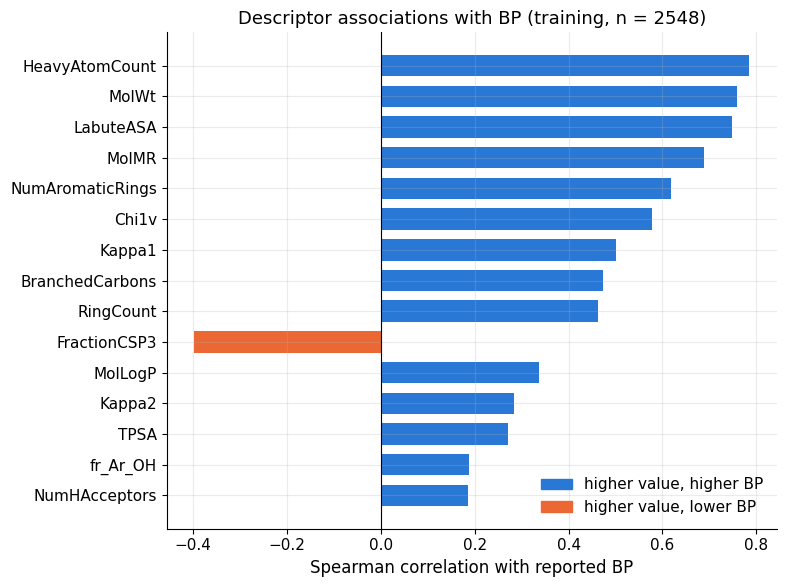

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig02_descriptor_bp_associations_training.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig02_descriptor_bp_associations_training.png')

In [12]:
train_desc = DESC.iloc[IDX['train']]
rho = train_desc.corrwith(pd.Series(y_all[IDX['train']], index=train_desc.index), method='spearman').dropna()
top = rho.reindex(rho.abs().sort_values().index)[-15:]
fig, ax = plt.subplots(figsize=(8, 6))
colors = [COLORS['blue'] if v > 0 else COLORS['orange'] for v in top]
ax.barh(top.index, top.values, color=colors, height=0.7)
ax.axvline(0, color='black', lw=0.8)
ax.set(xlabel='Spearman correlation with reported BP', title=f'Descriptor associations with BP (training, n = {len(train_desc)})')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS['blue']), plt.Rectangle((0, 0), 1, 1, color=COLORS['orange'])],
          labels=['higher value, higher BP', 'higher value, lower BP'], loc='lower right')
save_figure(fig, 'fig02_descriptor_bp_associations_training')

**Measured finding (training only).** The strongest rank correlations with BP are size and polarizability measures (molar refractivity, surface area, molecular weight, heavy atoms, Chi/Kappa), followed by polarity (TPSA). Branching and symmetry carry weaker, negative associations. These are associations: size descriptors are strongly correlated with each other, so their individual ranking should not be read as separate causes.

<h2 style="color:#1D4E89;">Step 6: Algorithm</h2>


Choose models that suit a few thousand molecules and these representations, give them one shared interface, and set a baseline before fitting anything clever.

**Decision: baseline and candidate models.**
- **Training-median baseline:** predicts the same number for every molecule. Any useful model must beat it clearly.
- **Ridge regression:** an interpretable linear reference. Strength: stable, fast, extrapolates linearly. Weakness: misses curvature and interactions.
- **RBF support-vector regression (SVR):** a smooth kernel method that works well on a few dozen standardized descriptors and uses an outlier-tolerant ε-insensitive loss. Weakness: sensitive to feature scaling and to many sparse columns; reverts toward the mean far from training data.
- **Histogram gradient boosting (HGB):** captures nonlinear interactions and handles fingerprints and missing values. It is iterative, so we record its training history and stop at the best validation iteration. Weakness: piecewise-constant, so it cannot extrapolate beyond training BPs.

Every candidate goes through the same `fit_candidate` function so training and inference apply identical transformations. Non-iterative models get no invented epoch history.

### Model builders and one shared fit interface

Code Summary: Defines builders for every model family with learned preprocessing inside the estimator, so it is fit on training rows only. Boosted models record train and validation error per iteration and are refit at the best iteration, which restores the best checkpoint exactly.


In [13]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

HGB_DEFAULTS = dict(learning_rate=0.05, max_iter=1500, max_leaf_nodes=31, min_samples_leaf=10,
                    l2_regularization=0.0, early_stopping=False, random_state=SEED)
SVR_DEFAULTS = dict(C=10.0, epsilon=0.05, gamma='scale')
PRIOR_COLUMNS = ['MolMR', 'TPSA', 'NumHDonors', 'BranchedCarbons']  # size, polarity, H-bonding, branching


def build_model(family, params, feature_columns):
    """Return an unfitted estimator; imputers and scalers live inside it."""
    if family == 'median_baseline':
        return DummyRegressor(strategy='median')
    if family == 'ridge':
        return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=params.get('alpha', 1.0)))
    if family == 'svr':
        svr = SVR(kernel='rbf', **{**SVR_DEFAULTS, **params})
        return TransformedTargetRegressor(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), svr),
                                          transformer=StandardScaler())
    if family == 'hgb':
        return HistGradientBoostingRegressor(**{**HGB_DEFAULTS, **params})
    if family.startswith('prior+'):
        prior_idx = tuple(feature_columns.index(c) for c in PRIOR_COLUMNS)
        return bp_inference.PriorResidualRegressor(prior_idx, build_model(family[len('prior+'):], params, feature_columns))
    raise ValueError(f'Unknown model family: {family}')


def is_iterative(family):
    return family.split('+')[-1] == 'hgb'


def split_xy(feature_set, split):
    cols = FEATURE_SETS[feature_set]
    return X_ALL.iloc[IDX[split]][cols].to_numpy(float), y_all[IDX[split]]


def fit_candidate(family, feature_set, params=None):
    """Fit on training rows only and return the model, predictions, metrics and history."""
    params, cols = dict(params or {}), FEATURE_SETS[feature_set]
    (X_tr, y_tr), (X_va, y_va) = split_xy(feature_set, 'train'), split_xy(feature_set, 'validation')
    start = time.perf_counter()
    model = build_model(family, params, cols).fit(X_tr, y_tr)
    history = None
    if is_iterative(family):  # validation-based stopping, then refit to the best iteration
        val_curve = [mean_absolute_error(y_va, p) for p in model.staged_predict(X_va)]
        train_curve = [mean_absolute_error(y_tr, p) for p in model.staged_predict(X_tr)]
        history = pd.DataFrame({'iteration': np.arange(1, len(val_curve) + 1),
                                'train_MAE_K': train_curve, 'validation_MAE_K': val_curve})
        params['max_iter'] = int(np.argmin(val_curve)) + 1
        model = build_model(family, params, cols).fit(X_tr, y_tr)
        assert np.isclose(mean_absolute_error(y_va, model.predict(X_va)), min(val_curve))
    pred_tr, pred_va = model.predict(X_tr), model.predict(X_va)
    return {'model': model, 'family': family, 'feature_set': feature_set, 'params': params,
            'history': history, 'fit_seconds': time.perf_counter() - start,
            'pred_train': pred_tr, 'pred_val': pred_va,
            'train': regression_metrics(y_tr, pred_tr), 'validation': regression_metrics(y_va, pred_va)}


print('Families:', ['median_baseline', 'ridge', 'svr', 'hgb', 'prior+<family>'])

Families: ['median_baseline', 'ridge', 'svr', 'hgb', 'prior+<family>']


### Training-median baseline

Code Summary: Fits the dummy baseline that predicts the training median for every molecule and reports its first validation error. Everything later must beat this number clearly.


In [14]:
baseline_result = fit_candidate('median_baseline', 'descriptors')
print(f"Training median: {np.median(y_all[IDX['train']]):.1f} K")
print(f"Baseline validation MAE: {baseline_result['validation']['MAE_K']:.2f} K "
      f"(n = {baseline_result['validation']['n']})")
STAGES.append('baseline')

Training median: 458.7 K
Baseline validation MAE: 56.15 K (n = 318)


<h2 style="color:#1D4E89;">Step 7: Experiment</h2>


Design fair experiments comparing models, settings, or representations on the fixed training and validation assignments. Keep the final test set untouched until Step 10, after Step 9 optimization and model selection are complete.

### Experiment tracker

Code Summary: Creates numbered experiment folders, each with metadata, train and validation predictions and a training history when one exists, plus a running summary table. A guard refuses to record any test-set row.


In [15]:
EXPERIMENTS = []


def log_experiment(name, hypothesis, result, notes=''):
    """Save one train/validation experiment and refresh experiment_summary.csv."""
    number = len(EXPERIMENTS) + 1
    folder = EXP_DIR / f'experiment_{number:03d}_{name}'
    folder.mkdir(parents=True)
    meta = {'experiment': number, 'name': name, 'hypothesis': hypothesis, 'family': result['family'],
            'feature_set': result['feature_set'], 'n_features': len(FEATURE_SETS[result['feature_set']]),
            'settings': {k: v for k, v in result['params'].items()}, 'seed': SEED,
            'fit_seconds': round(result['fit_seconds'], 2), 'train': result['train'],
            'validation': result['validation'], 'notes': notes}
    (folder / 'metadata.json').write_text(json.dumps(meta, indent=2, default=str) + '\n')
    preds = pd.concat([
        pd.DataFrame({'canonical_smiles': clean['canonical_smiles'].iloc[IDX[s]].to_numpy(), 'split': s,
                      'BP_K': y_all[IDX[s]], 'predicted_BP_K': result[f'pred_{k}']})
        for s, k in [('train', 'train'), ('validation', 'val')]])
    assert set(preds['split']) <= {'train', 'validation'}, 'Test rows must never enter an experiment.'
    preds.to_csv(folder / 'predictions.csv', index=False)
    if result['history'] is not None:
        result['history'].to_csv(folder / 'training_history.csv', index=False)
    EXPERIMENTS.append({'experiment': number, 'name': name, 'family': result['family'],
                        'feature_set': result['feature_set'], 'train_MAE_K': result['train']['MAE_K'],
                        'val_MAE_K': result['validation']['MAE_K'], 'val_RMSE_K': result['validation']['RMSE_K'],
                        'val_R2': result['validation']['R2'], 'fit_seconds': result['fit_seconds'],
                        'settings': json.dumps(result['params'], default=str), 'result': result})
    summary_table().to_csv(EXP_DIR / 'experiment_summary.csv', index=False)
    print(f"{number:03d} {name:<34} val MAE {result['validation']['MAE_K']:6.2f} K | "
          f"train MAE {result['train']['MAE_K']:6.2f} K | {result['fit_seconds']:5.1f} s")
    return result


def summary_table():
    """All experiments ranked by validation MAE (lower is better)."""
    rows = [{k: v for k, v in e.items() if k != 'result'} for e in EXPERIMENTS]
    return pd.DataFrame(rows).sort_values('val_MAE_K', ignore_index=True)


def get_experiment(name):
    return next(e['result'] for e in EXPERIMENTS if e['name'] == name)


log_experiment('median_baseline', 'Reference: predicting the training median for every molecule.', baseline_result)
STAGES.append('tracker')

001 median_baseline                    val MAE  56.15 K | train MAE  56.46 K |   0.0 s


<h3 style="color:#B05E27;">Experiment 1: model families and representations</h3>

Same split, same validation set, same interface. We compare three model families on descriptors, and the boosting model on each representation, plus ridge on the combined set.

### Compare model families and feature sets

Code Summary: Fits ridge, SVR and gradient boosting on descriptors, then gradient boosting on fingerprints and on descriptors plus fingerprints, and ridge on the combined set. Every result is logged with its hypothesis.


In [16]:
FAMILY_PLAN = [
    ('ridge_descriptors', 'ridge', 'descriptors', 'A linear combination of size, shape and polarity descriptors captures most of the BP trend.'),
    ('svr_descriptors', 'svr', 'descriptors', 'A smooth nonlinear kernel on the same descriptors captures curvature (e.g. diminishing BP gain per CH2).'),
    ('hgb_descriptors', 'hgb', 'descriptors', 'Trees capture interactions between descriptors (e.g. H-bonding matters more for small molecules).'),
    ('hgb_morgan', 'hgb', 'morgan', 'Local substructure counts alone carry enough size and functional-group information.'),
    ('hgb_descriptors_morgan', 'hgb', 'descriptors+morgan', 'Fingerprints add substructure detail the descriptors miss.'),
    ('ridge_descriptors_morgan', 'ridge', 'descriptors+morgan', 'Adding fingerprints to a linear model helps if substructure effects are roughly additive.'),
]
for name, family, feature_set, hypothesis in FAMILY_PLAN:
    log_experiment(name, hypothesis, fit_candidate(family, feature_set))
display(summary_table().drop(columns=['settings']).round(2))

002 ridge_descriptors                  val MAE  17.83 K | train MAE  16.81 K |   0.0 s


003 svr_descriptors                    val MAE  12.94 K | train MAE   6.39 K |   1.0 s


004 hgb_descriptors                    val MAE  15.16 K | train MAE   4.92 K |   6.2 s


005 hgb_morgan                         val MAE  18.31 K | train MAE   4.30 K |  26.1 s


006 hgb_descriptors_morgan             val MAE  14.43 K | train MAE   3.97 K |  18.9 s


007 ridge_descriptors_morgan           val MAE  26.20 K | train MAE  11.21 K |   0.3 s


,experiment,name,family,feature_set,train_MAE_K,val_MAE_K,val_RMSE_K,val_R2,fit_seconds
0,3,svr_descriptors,svr,descriptors,6.39,12.94,30.09,0.84,0.96
1,6,hgb_descriptors_morgan,hgb,descriptors+morgan,3.97,14.43,31.85,0.82,18.94
2,4,hgb_descriptors,hgb,descriptors,4.92,15.16,31.63,0.82,6.22
3,2,ridge_descriptors,ridge,descriptors,16.81,17.83,34.66,0.78,0.01
4,5,hgb_morgan,hgb,morgan,4.30,18.31,34.37,0.79,26.12
5,7,ridge_descriptors_morgan,ridge,descriptors+morgan,11.21,26.20,42.70,0.67,0.34
6,1,median_baseline,median_baseline,descriptors,56.46,56.15,74.36,-0.01,0.00


**Measured finding: model families.** Every model beats the 56.1 K median baseline by a wide margin. **SVR on the 34 descriptors is best (12.9 K)**, ahead of boosting on descriptors + fingerprints (14.4 K), boosting on descriptors (15.2 K), ridge on descriptors (17.8 K) and boosting on fingerprints alone (18.3 K). Adding 1024 sparse fingerprint columns *hurt* ridge (26.2 K, with a large train/validation gap). This is a classic overfitting signature when columns far outnumber what about 2500 molecules can support. In the first prototype, fingerprints also hurt SVR, because they swamp the kernel's distance. Boosting gains a little from them. Ridge's small train/validation gap (16.8 vs 17.8 K) shows it is limited by bias, not overfitting.

<h3 style="color:#B05E27;">Experiment 2: controlled feature ablation</h3>

Remove only the hydrogen-bond descriptors from the best descriptor model and compare overall and for molecules with an H-bond donor.

**Decision: test whether hydrogen-bond counts earn their place.**
Reasoning: (1) Ethanol (46 g/mol, BP about 351 K) boils far above propane (44 g/mol, about 231 K), so mass alone misses intermolecular hydrogen bonding. (2) RDKit counts donors and acceptors from SMILES alone, so the feature is available at inference. (3) Hypothesis: removing these counts raises validation error most for molecules with an H-bond donor. TPSA stays in both versions, so some polarity information remains.
Test: same family, settings and split; compare validation MAE overall and for the donor subgroup.

### H-bond descriptor ablation

Code Summary: Refits the best descriptor-only model family without the seven hydrogen-bond descriptors and compares validation error overall and for molecules with and without an H-bond donor, with counts.


In [17]:
desc_runs = summary_table().query("feature_set == 'descriptors' and family != 'median_baseline'")
ABLATION_FAMILY = desc_runs.iloc[0]['family']
control = get_experiment(desc_runs.iloc[0]['name'])
ablated = log_experiment(f'{ABLATION_FAMILY}_descriptors_without_hbond',
                         'Removing H-bond counts hurts most for molecules with H-bond donors.',
                         fit_candidate(ABLATION_FAMILY, 'descriptors_without_hbond'))
y_val = y_all[IDX['validation']]
has_donor = DESC['NumHDonors'].to_numpy()[IDX['validation']] > 0
rows = []
for label, mask in [('all validation', np.ones_like(has_donor)), ('H-bond donor present', has_donor), ('no H-bond donor', ~has_donor)]:
    rows.append({'subgroup': label, 'n': int(mask.sum()),
                 'with H-bond features (K)': mean_absolute_error(y_val[mask], control['pred_val'][mask]),
                 'without H-bond features (K)': mean_absolute_error(y_val[mask], ablated['pred_val'][mask])})
ablation_table = pd.DataFrame(rows).assign(change_K=lambda d: d.iloc[:, 3] - d.iloc[:, 2])
display(ablation_table.round(2))

008 svr_descriptors_without_hbond      val MAE  13.81 K | train MAE   6.94 K |   1.0 s


,subgroup,n,with H-bond features (K),without H-bond features (K),change_K
0,all validation,318,12.94,13.81,0.87
1,H-bond donor present,87,13.65,15.15,1.50
2,no H-bond donor,231,12.67,13.31,0.64


**Measured finding: H-bond ablation.** Removing the seven H-bond descriptors raises validation MAE by 0.9 K overall. For molecules with a donor (n = 87) it rises by 1.5 K, and for those without (n = 231) by 0.6 K. The direction matches the hypothesis. The effect is modest, likely because TPSA and heteroatom counts still carry much of the polarity information, and with 87 molecules a 1.5 K difference is suggestive rather than conclusive. We keep the H-bond descriptors.

<h3 style="color:#B05E27;">Experiment 3: modest settings search</h3>

A small, bounded grid for the leading family only, on the frozen train/validation split. We do not keep searching until a desired score appears.

### Bounded settings search for the leading family

Code Summary: Takes the best family and feature set so far and tries a small fixed grid of its main settings, logging each run. The grid is declared before running and is not extended after seeing results.


In [18]:
SEARCH_GRIDS = {
    'svr': [dict(C=c, epsilon=e, gamma=g) for c in (3.0, 10.0, 30.0, 100.0) for e in (0.02, 0.1) for g in ('scale', 0.01)],
    'hgb': [dict(max_leaf_nodes=m, min_samples_leaf=s) for m in (15, 31, 63) for s in (5, 20)],
    'ridge': [dict(alpha=a) for a in (0.1, 1.0, 10.0, 100.0)],
}
leader = summary_table().query("family != 'median_baseline'").iloc[0]
SEARCH_FAMILY, SEARCH_FEATURES = leader['family'], leader['feature_set']
print(f'Leading configuration: {leader["name"]} ({leader["val_MAE_K"]:.2f} K); grid of {len(SEARCH_GRIDS[SEARCH_FAMILY])} settings')
search_rows = []
for params in SEARCH_GRIDS[SEARCH_FAMILY]:
    tag = '_'.join(f'{k}{v}' for k, v in params.items())
    res = log_experiment(f'{SEARCH_FAMILY}_search_{tag}', 'Settings search on the leading family.',
                         fit_candidate(SEARCH_FAMILY, SEARCH_FEATURES, params))
    search_rows.append({**params, 'train_MAE_K': res['train']['MAE_K'], 'val_MAE_K': res['validation']['MAE_K']})
search_table = pd.DataFrame(search_rows).sort_values('val_MAE_K', ignore_index=True)
display(search_table.round(2))
TUNED_PARAMS = {k: (v.item() if hasattr(v, 'item') else v)  # plain Python numbers for JSON and printing
                for k, v in search_table.iloc[0].items() if k in SEARCH_GRIDS[SEARCH_FAMILY][0]}
TUNED_NAME = f"{SEARCH_FAMILY}_search_{'_'.join(f'{k}{v}' for k, v in TUNED_PARAMS.items())}"
print(f'Best settings on validation: {TUNED_PARAMS}')

Leading configuration: svr_descriptors (12.94 K); grid of 16 settings


009 svr_search_C3.0_epsilon0.02_gammascale val MAE  13.12 K | train MAE   7.12 K |   0.8 s


010 svr_search_C3.0_epsilon0.02_gamma0.01 val MAE  13.43 K | train MAE   9.89 K |   0.7 s


011 svr_search_C3.0_epsilon0.1_gammascale val MAE  13.21 K | train MAE   8.49 K |   0.4 s


012 svr_search_C3.0_epsilon0.1_gamma0.01 val MAE  13.67 K | train MAE  10.50 K |   0.4 s


013 svr_search_C10.0_epsilon0.02_gammascale val MAE  12.86 K | train MAE   5.72 K |   1.3 s


... (9 outputs left out)

023 svr_search_C100.0_epsilon0.1_gammascale val MAE  14.33 K | train MAE   6.53 K |   1.9 s


024 svr_search_C100.0_epsilon0.1_gamma0.01 val MAE  12.87 K | train MAE   7.64 K |   1.5 s


,C,epsilon,gamma,train_MAE_K,val_MAE_K
0,10.0,0.02,0.01,8.38,12.43
1,30.0,0.02,0.01,7.11,12.49
2,100.0,0.02,0.01,6.09,12.59
3,30.0,0.10,0.01,8.32,12.76
4,10.0,0.10,0.01,9.30,12.86
5,10.0,0.02,scale,5.72,12.86
6,100.0,0.10,0.01,7.64,12.87
7,3.0,0.02,scale,7.12,13.12
8,30.0,0.02,scale,4.78,13.19
9,3.0,0.10,scale,8.49,13.21


Best settings on validation: {'C': 10.0, 'epsilon': 0.02, 'gamma': 0.01}


### Validation error versus settings

Code Summary: Plots validation and training MAE for each setting in the grid so the learner can see where extra flexibility starts to overfit.


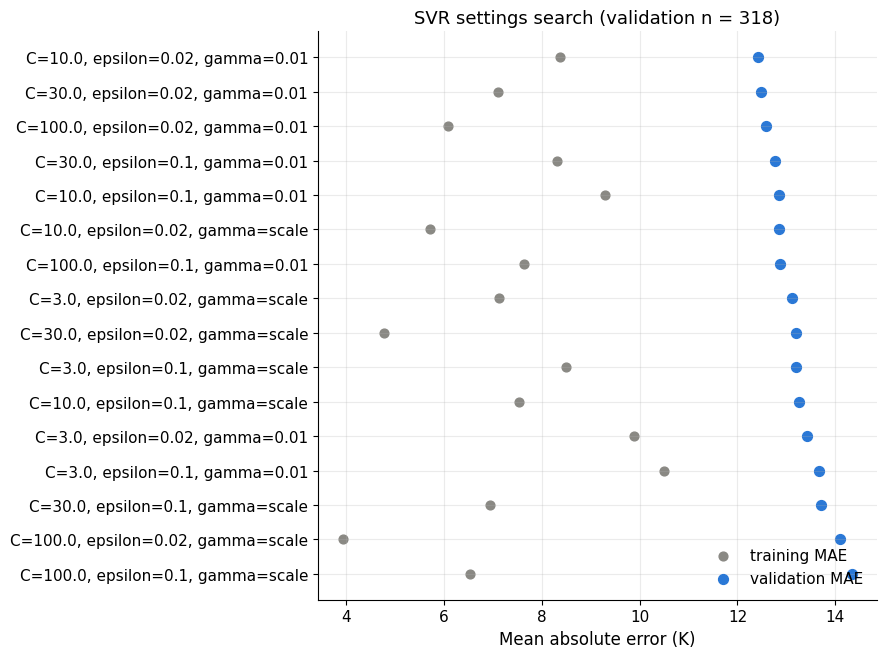

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig03_settings_search.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig03_settings_search.png')

In [19]:
labels = [', '.join(f'{k}={v}' for k, v in r.items() if k in TUNED_PARAMS) for r in search_rows]
order = np.argsort([r['val_MAE_K'] for r in search_rows])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(order) + 1.6))
ypos = np.arange(len(order))
ax.scatter([search_rows[i]['train_MAE_K'] for i in order], ypos, color=COLORS['gray'], s=40, label='training MAE')
ax.scatter([search_rows[i]['val_MAE_K'] for i in order], ypos, color=COLORS['blue'], s=50, label='validation MAE')
ax.set_yticks(ypos, [labels[i] for i in order])
ax.invert_yaxis()
ax.set(xlabel='Mean absolute error (K)', title=f'{SEARCH_FAMILY.upper()} settings search (validation n = {len(IDX["validation"])})')
ax.legend(loc='lower right')
save_figure(fig, 'fig03_settings_search')

**Measured finding: settings search.** All 16 settings land between 12.4 and 14.3 K, so SVR is not very sensitive in this range. The best is C = 10, ε = 0.02, γ = 0.01 (12.4 K). A smaller γ than the default (`'scale'` ≈ 0.03 here) means a smoother kernel. Large C with the default γ fits the training set closely (3.9 K) but validates worse (14.1 K), which is the overfitting pattern the figure makes visible. The 0.5 K gain over the default settings is below our 1 K "meaningful" threshold. We keep the tuned settings because the search was declared in advance and costs nothing extra to deploy, but we do not claim tuning mattered much.

<h3 style="color:#B05E27;">Experiment 4: creative enhancement</h3>

Three ideas, rated before running anything; we implement two and judge them against criteria fixed in advance.

| Idea | Expected benefit | Cost | Risk |
|---|---|---|---|
| **A. Physics prior + learned residual:** a linear trend in molar refractivity (size/polarizability), TPSA (polarity), donors (H-bonding) and branch points, with the tuned model learning only what the trend misses | Better behaviour for very small and very large molecules, where a kernel model reverts toward the mean | Low | Low; the prior is fit on training rows only |
| **B. Applicability-domain score:** nearest-training-molecule Tanimoto similarity shown beside each prediction | More *useful* predictions: users see when a molecule is unfamiliar | Low | None for accuracy; risk of being over-read as a probability |
| C. Two-family ensemble (SVR + boosting) with disagreement as a warning | Small accuracy gain plus an uncertainty signal | Medium | Harder to explain; spread is not a calibrated interval |

**Chosen: A and B.** C is held back as a candidate for Step 9.

**Pre-registered success criteria.**
- **A helped** only if it lowers validation MAE by at least **1.0 K** versus the identical model without the prior, and the self-consistency checks in Step 8 agree.
- **B is useful** only if validation error is clearly larger for low-similarity molecules than for high-similarity ones (MAE in the out-of-domain band greater than in the in-domain band, and a negative rank correlation between similarity and absolute error).

We do not report prediction intervals: we have no data set aside for calibration, and similarity is not a probability.

### Enhancement A: physics prior plus learned residual

Code Summary: Fits the tuned model on residuals from a training-only linear prior and compares it with the identical model without the prior, overall and by molecular size, against the 1 K criterion.


In [20]:
control_result = get_experiment(TUNED_NAME)
prior_result = log_experiment(f'prior+{TUNED_NAME}', 'A linear size/polarity prior helps at the size extremes.',
                              fit_candidate(f'prior+{SEARCH_FAMILY}', SEARCH_FEATURES, TUNED_PARAMS))
Xp_val, _ = split_xy(SEARCH_FEATURES, 'validation')
prior_only_mae = mean_absolute_error(y_val, prior_result['model'].predict_prior(Xp_val))
heavy_val = DESC['HeavyAtomCount'].to_numpy()[IDX['validation']]
SIZE_BINS = [(1, 6, '1-6'), (7, 9, '7-9'), (10, 12, '10-12'), (13, 999, '13+')]
rows = []
for lo, hi, label in SIZE_BINS:
    mask = (heavy_val >= lo) & (heavy_val <= hi)
    rows.append({'heavy atoms': label, 'n': int(mask.sum()),
                 'control MAE (K)': mean_absolute_error(y_val[mask], control_result['pred_val'][mask]),
                 'prior + residual MAE (K)': mean_absolute_error(y_val[mask], prior_result['pred_val'][mask])})
display(pd.DataFrame(rows).round(2))
GAIN_A = control_result['validation']['MAE_K'] - prior_result['validation']['MAE_K']
print(f"Linear prior alone: {prior_only_mae:.2f} K | control: {control_result['validation']['MAE_K']:.2f} K | "
      f"prior + residual: {prior_result['validation']['MAE_K']:.2f} K")
print(f'Validation gain from the prior: {GAIN_A:+.2f} K (criterion: >= {MEANINGFUL_GAIN_K} K) -> '
      f"{'meets' if GAIN_A >= MEANINGFUL_GAIN_K else 'does not meet'} the pre-registered threshold")

025 prior+svr_search_C10.0_epsilon0.02_gamma0.01 val MAE  12.71 K | train MAE   8.95 K |   0.9 s


,heavy atoms,n,control MAE (K),prior + residual MAE (K)
0,1-6,33,15.16,15.84
1,7-9,126,8.18,8.82
2,10-12,110,13.81,13.73
3,13+,49,18.41,18.31


Linear prior alone: 30.93 K | control: 12.43 K | prior + residual: 12.71 K
Validation gain from the prior: -0.28 K (criterion: >= 1.0 K) -> does not meet the pre-registered threshold


### Enhancement B: applicability-domain similarity

Code Summary: Computes each validation molecule's highest Tanimoto similarity to any training molecule and checks whether validation error rises as similarity falls, using the bands fixed in the configuration cell.


,n,MAE_K,median_K
band,,,
in-domain,233,12.77,5.60
borderline,77,8.89,5.86
out-of-domain,8,36.34,18.56


Spearman(similarity, |error|) = -0.17; useful by the pre-registered rule: True


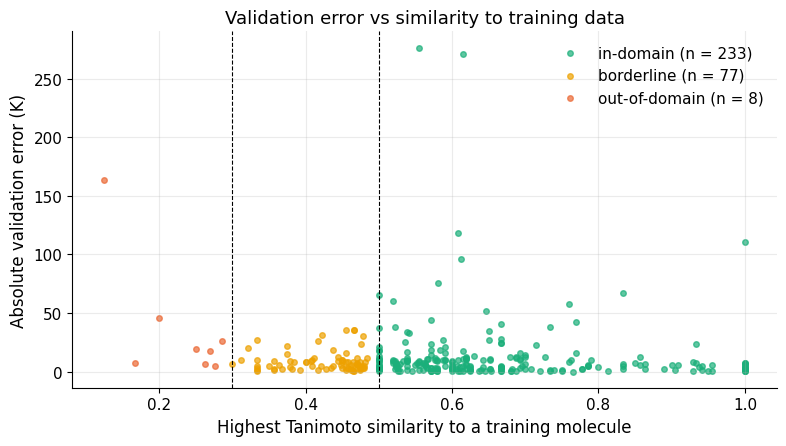

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig04_applicability_domain_validation.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig04_applicability_domain_validation.png')

In [21]:
train_ids = clean['canonical_smiles'].iloc[IDX['train']].tolist()
train_fps = bp_inference.similarity_fingerprints([clean_mols[i] for i in IDX['train']], MORGAN_RADIUS, SIMILARITY_BITS)


def max_similarity(split):
    fps = bp_inference.similarity_fingerprints([clean_mols[i] for i in IDX[split]], MORGAN_RADIUS, SIMILARITY_BITS)
    return bp_inference.nearest_neighbors(fps, train_fps)


def ad_band(sim):
    return np.where(sim >= AD_THRESHOLDS['in-domain'], 'in-domain',
                    np.where(sim >= AD_THRESHOLDS['borderline'], 'borderline', 'out-of-domain'))


sim_val, nn_val = max_similarity('validation')
abs_err_val = np.abs(y_val - control_result['pred_val'])
band_val = ad_band(sim_val)
ad_table = (pd.DataFrame({'band': band_val, 'abs_error_K': abs_err_val})
            .groupby('band')['abs_error_K'].agg(n='size', MAE_K='mean', median_K='median')
            .reindex(['in-domain', 'borderline', 'out-of-domain']))
display(ad_table.round(2))
AD_SPEARMAN = pd.Series(sim_val).corr(pd.Series(abs_err_val), method='spearman')
AD_USEFUL = bool(ad_table.loc['out-of-domain', 'MAE_K'] > ad_table.loc['in-domain', 'MAE_K'] and AD_SPEARMAN < 0)
print(f'Spearman(similarity, |error|) = {AD_SPEARMAN:.2f}; useful by the pre-registered rule: {AD_USEFUL}')

fig, ax = plt.subplots(figsize=(8, 4.6))
for band, color in [('in-domain', COLORS['aqua']), ('borderline', COLORS['yellow']), ('out-of-domain', COLORS['orange'])]:
    m = band_val == band
    ax.scatter(sim_val[m], abs_err_val[m], s=16, alpha=0.7, color=color, label=f'{band} (n = {m.sum()})')
for thr in AD_THRESHOLDS.values():
    ax.axvline(thr, color='black', lw=0.8, ls='--')
ax.set(xlabel='Highest Tanimoto similarity to a training molecule', ylabel='Absolute validation error (K)',
       title='Validation error vs similarity to training data')
ax.legend(loc='upper right')
save_figure(fig, 'fig04_applicability_domain_validation')

**Measured finding: creative enhancements, judged against the pre-registered criteria.**
- **A (physics prior + residual) did not help.** The linear prior alone reaches 30.9 K. Adding the SVR residual gives 12.7 K, which is 0.3 K *worse* than the same SVR without the prior. It was not better at the size extremes either (within ±0.7 K in every size bin). A plausible explanation: with a small γ the RBF-SVR already captures the smooth size trend, so the prior adds nothing and its errors propagate. **Decision: not adopted.**
- **B (applicability domain) is useful, but only as a coarse warning.** The rule passes: out-of-domain molecules (similarity < 0.3) have 36 K MAE against 13 K in-domain, and the rank correlation is negative (−0.17). However, only 8 validation molecules are out-of-domain, and the *borderline* band is more accurate than the in-domain band. The largest errors (about 270 K) sit at in-domain similarities of 0.55–0.62. Those errors come from suspect labels, which no similarity score can detect. **Decision: report similarity and nearest neighbour with every prediction, described as a warning, not a confidence.**

### Validation comparison of all experiments

Code Summary: Draws one bar per experiment, sorted by validation MAE and colored by model family, with the median baseline for reference. Only validation data are used.


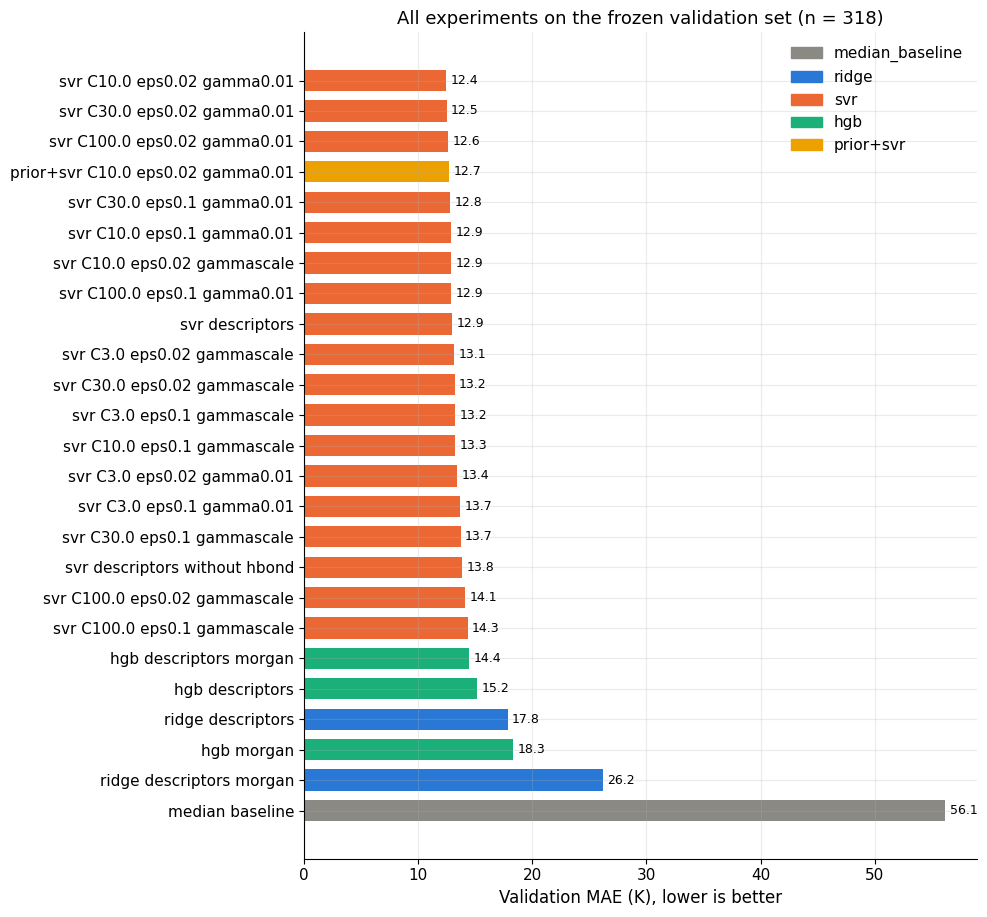

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig05_validation_comparison_all_experiments.png


In [22]:
summary = summary_table()
family_colors = {'median_baseline': COLORS['gray'], 'ridge': COLORS['blue'], 'svr': COLORS['orange'],
                 'hgb': COLORS['aqua'], f'prior+{SEARCH_FAMILY}': COLORS['yellow']}
fig, ax = plt.subplots(figsize=(10, 0.3 * len(summary) + 1.8))
short = summary['name'].str.replace('_search_', ' ').str.replace('epsilon', 'eps').str.replace('_', ' ')
ax.barh(short, summary['val_MAE_K'], color=[family_colors[f] for f in summary['family']], height=0.7)
for y, v in enumerate(summary['val_MAE_K']):
    ax.text(v + 0.4, y, f'{v:.1f}', va='center', fontsize=9)
ax.invert_yaxis()
ax.set(xlabel='Validation MAE (K), lower is better', title=f'All experiments on the frozen validation set (n = {len(IDX["validation"])})')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in family_colors.values()],
          labels=list(family_colors), loc='upper right')
save_figure(fig, 'fig05_validation_comparison_all_experiments')
STAGES.append('experiments')

<h2 style="color:#1D4E89;">Step 8: Analysis</h2>


Analyze validation experiments and identify the most promising configuration and its limitations. **Refinement of the template:** the test set stays sealed here too, because Step 9 can still change the model; looking at test results now would quietly turn the test set into a second validation set.

### Rank experiments and inspect the train/validation gap

Code Summary: Ranks every experiment by validation MAE, shows the gap between training and validation error, and names the current best configuration and the best configuration from a different model family.


In [23]:
ranked = summary_table().assign(gap_K=lambda d: d['val_MAE_K'] - d['train_MAE_K'])
display(ranked[['name', 'family', 'feature_set', 'train_MAE_K', 'val_MAE_K', 'gap_K', 'val_R2']].round(2))
candidates = ranked[~ranked['family'].str.startswith('prior+') & (ranked['family'] != 'median_baseline')]
BEST_NAME = candidates.iloc[0]['name']
BEST_LABEL = f"{candidates.iloc[0]['family'].upper()} on {candidates.iloc[0]['feature_set']}"
RUNNER_UP_NAME = candidates[candidates['family'] != candidates.iloc[0]['family']].iloc[0]['name']
best = get_experiment(BEST_NAME)
print(f'Current best: {BEST_NAME} ({best["validation"]["MAE_K"]:.2f} K); '
      f'best other family: {RUNNER_UP_NAME} ({get_experiment(RUNNER_UP_NAME)["validation"]["MAE_K"]:.2f} K)')

,name,family,feature_set,train_MAE_K,val_MAE_K,gap_K,val_R2
0,svr_search_C10.0_epsilon0.02_gamma0.01,svr,descriptors,8.38,12.43,4.05,0.84
1,svr_search_C30.0_epsilon0.02_gamma0.01,svr,descriptors,7.11,12.49,5.38,0.84
2,svr_search_C100.0_epsilon0.02_gamma0.01,svr,descriptors,6.09,12.59,6.50,0.84
3,prior+svr_search_C10.0_epsilon0.02_gamma0.01,prior+svr,descriptors,8.95,12.71,3.76,0.84
4,svr_search_C30.0_epsilon0.1_gamma0.01,svr,descriptors,8.32,12.76,4.44,0.84
5,svr_search_C10.0_epsilon0.1_gamma0.01,svr,descriptors,9.30,12.86,3.56,0.84
6,svr_search_C10.0_epsilon0.02_gammascale,svr,descriptors,5.72,12.86,7.13,0.84
7,svr_search_C100.0_epsilon0.1_gamma0.01,svr,descriptors,7.64,12.87,5.23,0.84
8,svr_descriptors,svr,descriptors,6.39,12.94,6.55,0.84
9,svr_search_C3.0_epsilon0.02_gammascale,svr,descriptors,7.12,13.12,6.01,0.83


Current best: svr_search_C10.0_epsilon0.02_gamma0.01 (12.43 K); best other family: hgb_descriptors_morgan (14.43 K)


### Training history of the best boosting run

Code Summary: Plots training and validation MAE against boosting iteration for the best gradient-boosting experiment and marks the restored best iteration.


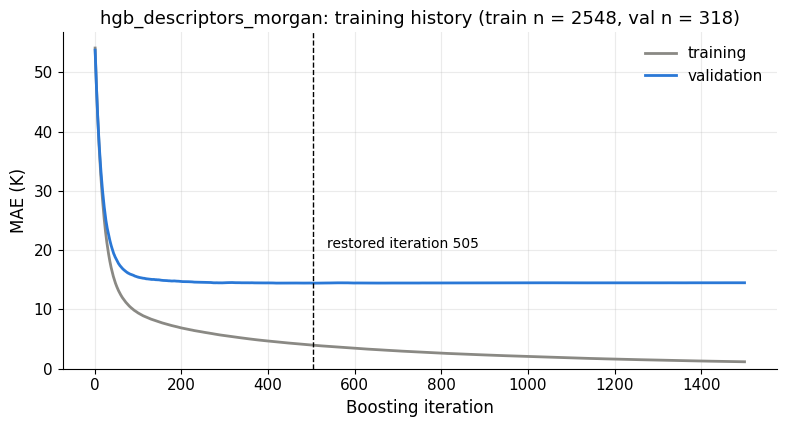

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig06_boosting_training_history.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig06_boosting_training_history.png')

In [24]:
hgb_name = ranked.query("family == 'hgb'").iloc[0]['name']
hist = get_experiment(hgb_name)['history']
best_iter = int(hist['validation_MAE_K'].idxmin()) + 1
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(hist['iteration'], hist['train_MAE_K'], color=COLORS['gray'], lw=2, label='training')
ax.plot(hist['iteration'], hist['validation_MAE_K'], color=COLORS['blue'], lw=2, label='validation')
ax.axvline(best_iter, color='black', ls='--', lw=1)
ax.annotate(f'restored iteration {best_iter}', (best_iter, hist['validation_MAE_K'].min()), xytext=(10, 25),
            textcoords='offset points', fontsize=10)
ax.set(xlabel='Boosting iteration', ylabel='MAE (K)', ylim=(0, None),
       title=f'{hgb_name}: training history (train n = {len(IDX["train"])}, val n = {len(IDX["validation"])})')
ax.legend()
save_figure(fig, 'fig06_boosting_training_history')

### Validation parity and residual plots

Code Summary: Plots predicted against reported boiling point and residuals against reported boiling point for the current best model on validation molecules, with the median baseline error for scale.


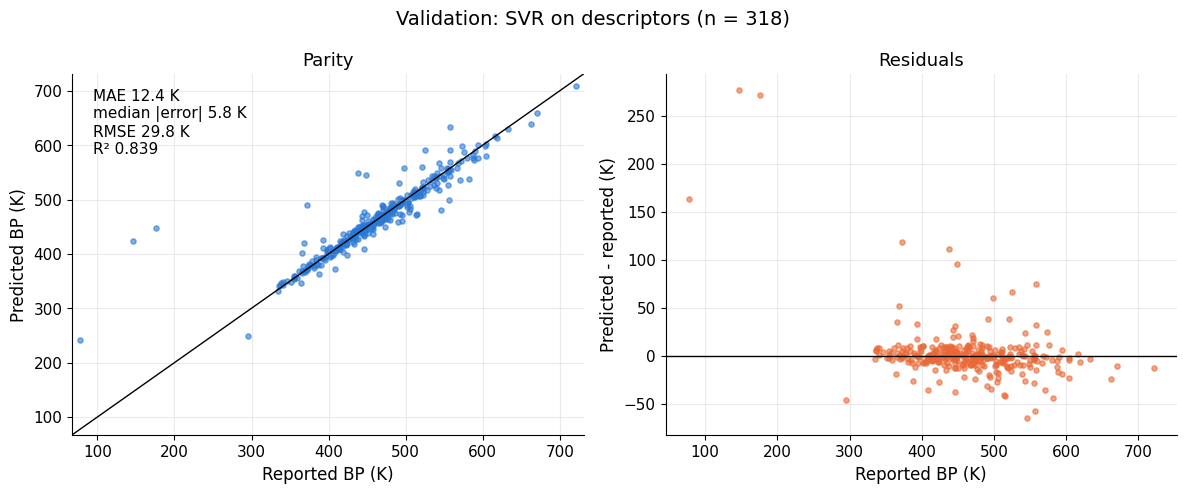

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig07_validation_parity_residuals.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig07_validation_parity_residuals.png')

In [25]:
def parity_and_residuals(y_true, y_pred, title, name):
    """Side-by-side parity and residual plots in kelvin."""
    m = regression_metrics(y_true, y_pred)
    resid = y_pred - y_true
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    lims = [min(y_true.min(), y_pred.min()) - 10, max(y_true.max(), y_pred.max()) + 10]
    axes[0].scatter(y_true, y_pred, s=14, alpha=0.6, color=COLORS['blue'])
    axes[0].plot(lims, lims, color='black', lw=1)
    fig.suptitle(f'{title} (n = {m["n"]})', fontsize=14)
    axes[0].set(xlim=lims, ylim=lims, xlabel='Reported BP (K)', ylabel='Predicted BP (K)', title='Parity')
    axes[0].text(0.04, 0.96, f"MAE {m['MAE_K']:.1f} K\nmedian |error| {m['MedAE_K']:.1f} K\nRMSE {m['RMSE_K']:.1f} K\nR² {m['R2']:.3f}",
                 transform=axes[0].transAxes, va='top')
    axes[1].scatter(y_true, resid, s=14, alpha=0.6, color=COLORS['orange'])
    axes[1].axhline(0, color='black', lw=1)
    axes[1].set(xlabel='Reported BP (K)', ylabel='Predicted - reported (K)', title='Residuals')
    return save_figure(fig, name)


parity_and_residuals(y_val, best['pred_val'], f'Validation: {BEST_LABEL}', 'fig07_validation_parity_residuals')

### Error by chemical subgroup

Code Summary: Breaks validation error down by hydrogen-bond donors, aromaticity, chlorine, nitrogen, sulfur, size and applicability band, for both the baseline and the current best model, with counts so small groups are not over-read.


In [26]:
def subgroup_masks(rows):
    """Boolean masks for chemically meaningful subgroups of the given row indices."""
    d = DESC.iloc[rows]
    heavy = d['HeavyAtomCount'].to_numpy()
    masks = {'all': np.ones(len(rows), bool),
             'H-bond donor present': d['NumHDonors'].to_numpy() > 0,
             'no H-bond donor': d['NumHDonors'].to_numpy() == 0,
             'aromatic': d['NumAromaticRings'].to_numpy() > 0,
             'chlorinated': d['count_Cl'].to_numpy() > 0,
             'contains N': d['count_N'].to_numpy() > 0,
             'contains S': d['count_S'].to_numpy() > 0}
    for lo, hi, label in SIZE_BINS:
        masks[f'{label} heavy atoms'] = (heavy >= lo) & (heavy <= hi)
    return masks


def subgroup_table(rows, y_true, preds):
    out = []
    for label, mask in subgroup_masks(rows).items():
        out.append({'subgroup': label, 'n': int(mask.sum()),
                    **{f'{k} MAE (K)': mean_absolute_error(y_true[mask], p[mask]) for k, p in preds.items()}})
    return pd.DataFrame(out)


baseline_val = np.full_like(y_val, np.median(y_all[IDX['train']]))
val_subgroups = subgroup_table(IDX['validation'], y_val, {'baseline': baseline_val, 'model': best['pred_val']})
for band in ['in-domain', 'borderline', 'out-of-domain']:
    m = ad_band(sim_val) == band
    val_subgroups.loc[len(val_subgroups)] = {'subgroup': f'AD: {band}', 'n': int(m.sum()),
                                             'baseline MAE (K)': mean_absolute_error(y_val[m], baseline_val[m]),
                                             'model MAE (K)': mean_absolute_error(y_val[m], best['pred_val'][m])}
display(val_subgroups.round(1))

,subgroup,n,baseline MAE (K),model MAE (K)
0,all,318,56.1,12.4
1,H-bond donor present,87,53.4,12.0
2,no H-bond donor,231,57.2,12.6
3,aromatic,117,67.3,12.4
4,chlorinated,44,47.0,9.0
5,contains N,78,64.0,13.8
6,contains S,18,45.4,10.4
7,1-6 heavy atoms,33,90.5,15.2
8,7-9 heavy atoms,126,41.2,8.2
9,10-12 heavy atoms,110,42.3,13.8


**Measured finding: subgroups.** The model's error is fairly even across chemistry: about 12 K with or without donors, 12 K for aromatics, 9 K for chlorinated (n = 44) and 14 K for nitrogen-containing (n = 78) molecules. It is uneven across **size**: 8 K for 7–9 heavy atoms (n = 126), but 15 K for the smallest (n = 33) and 18 K for the largest (n = 49). These edges have fewer training examples, and they hold the gases and the long-chain esters and acids, whose labels look most suspect. Groups with fewer than about 30 molecules (sulfur, n = 18; out-of-domain, n = 8) should not be over-read.

### Representative successes and failures

Code Summary: Lists the best-predicted and worst-predicted validation molecules with their nearest training molecule and its boiling point, so errors can be read chemically.


In [27]:
val_ids = clean['canonical_smiles'].iloc[IDX['validation']].to_numpy()
cases = pd.DataFrame({'molecule': val_ids, 'reported_K': y_val, 'predicted_K': best['pred_val'],
                      'error_K': best['pred_val'] - y_val, 'similarity': sim_val,
                      'nearest_train': [train_ids[j] for j in nn_val],
                      'nearest_train_K': y_all[IDX['train']][nn_val]})
cases['abs_error_K'] = cases['error_K'].abs()
print('Successes (smallest errors):')
display(cases.nsmallest(3, 'abs_error_K').drop(columns='abs_error_K').round(2))
print('Failures (largest errors):')
display(cases.nlargest(6, 'abs_error_K').drop(columns='abs_error_K').round(2))

Successes (smallest errors):


,molecule,reported_K,predicted_K,error_K,similarity,nearest_train,nearest_train_K
176,CCCCOCCOC,419.7,419.66,-0.04,0.76,CCCCOCCOCCCC,478.95
81,CC(O)C(C)(C)C,393.2,393.12,-0.08,0.62,CC(O)C(C)(C)O,446.65
75,CC(C)O[N+](=O)[O-],373.7,373.62,-0.08,0.55,CCC(C)O[N+](=O)[O-],397.15


Failures (largest errors):


,molecule,reported_K,predicted_K,error_K,similarity,nearest_train,nearest_train_K
125,CCC(OC(C)C)OC(C)C,146.50,423.18,276.68,0.56,CCC(C)OC(C)C,373.20
175,CCCCOC(=O)CC(C)C,175.70,446.97,271.27,0.62,CCCCOC(=O)CCC(=O)OCCCC,408.00
271,N#N,77.34,240.76,163.42,0.12,N#CC#CC#N,349.70
172,CCCCCOC(C)OCCCCC,372.45,490.57,118.12,0.61,CCCCCCCCOC(C)CC,487.20
161,CCCCCCCCCCC(=O)O,438.15,549.05,110.90,1.00,CCCCCCCCCCCCCCCC(=O)O,612.15
152,CCCCCCC(=O)Oc1ccccc1,448.65,544.69,96.04,0.61,CCC(=O)Oc1ccccc1,485.15


**Chemical reading of successes and failures (hypotheses, not proofs).**
- *Successes* are ordinary ethers, alcohols and nitrate esters with close training analogues, where the descriptors interpolate between neighbours.
- *Suspect labels, not model failures:* butyl isovalerate reported at 175.7 K and the acetal `CCC(OC(C)C)OC(C)C` at 146.5 K are liquids at room temperature (over 290 K), so these values are almost certainly wrong. They are probably mis-assigned or reduced-pressure entries. Undecanoic acid at 438 K is about 120 K below its usual atmospheric value, which is consistent with a reduced-pressure measurement. The model's predictions (447, 423 and 549 K) are chemically sensible.
- *Genuine extrapolation failure:* N₂ (77 K) has nothing like it in training (similarity 0.12), and the smooth kernel reverts toward the dataset average.
- *Note on similarity:* undecanoic acid has similarity **1.00** to hexadecanoic acid. Radius-2 Morgan bits cannot tell chain lengths apart beyond a few carbons, so a similarity of 1.0 does **not** mean "same molecule".

### Which inputs does the model rely on?

Code Summary: Measures how much validation error rises when each descriptor is shuffled, averaged over five shuffles, and plots the largest effects. These are associations inside this model, not causes of boiling point.


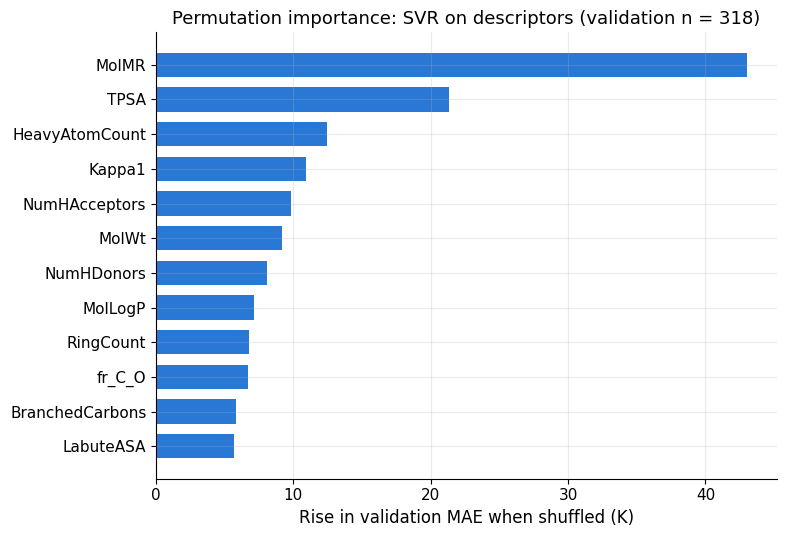

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig08_permutation_importance_validation.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig08_permutation_importance_validation.png')

In [28]:
def permutation_importance_k(result, n_repeats=5):
    """Increase in validation MAE when one column is shuffled (feature sets as in the result)."""
    cols = FEATURE_SETS[result['feature_set']]
    X_va, _ = split_xy(result['feature_set'], 'validation')
    base = mean_absolute_error(y_val, result['model'].predict(X_va))
    rng = np.random.default_rng(SEED)
    groups = {c: [cols.index(c)] for c in cols if c in DESCRIPTOR_COLS}
    if any(c in MORGAN_COLS for c in cols):
        groups['all Morgan bits (as one block)'] = [i for i, c in enumerate(cols) if c in MORGAN_COLS]
    out = {}
    for name, idx in groups.items():
        rises = []
        for _ in range(n_repeats):
            Xp = X_va.copy()
            Xp[:, idx] = Xp[rng.permutation(len(Xp))][:, idx]
            rises.append(mean_absolute_error(y_val, result['model'].predict(Xp)) - base)
        out[name] = np.mean(rises)
    return pd.Series(out).sort_values()


importance = permutation_importance_k(best)
top_imp = importance[-12:]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_imp.index, top_imp.values, color=COLORS['blue'], height=0.7)
ax.set(xlabel='Rise in validation MAE when shuffled (K)',
       title=f'Permutation importance: {BEST_LABEL} (validation n = {len(y_val)})')
save_figure(fig, 'fig08_permutation_importance_validation')

**Measured finding: what the model relies on.** Shuffling molar refractivity (a polarizability/size proxy) raises validation MAE by about 43 K, far more than any other input. TPSA (polarity) comes next, then heavy-atom count, Kappa1 (shape), H-bond acceptors, molecular weight and donors. This ordering matches the chemist's hypotheses: dispersion first, then polarity and hydrogen bonding, then shape. But these are associations *inside this model*. Correlated descriptors share credit unpredictably, so a small importance does not mean a mechanism is unimportant in reality.

<h3 style="color:#B05E27;">Self-consistency: check the two key conclusions a second way</h3>

Which model wins, and whether enhancement A helps, are each checked with a paired bootstrap of the validation set and with 5-fold cross-validation inside the training set. These models are deterministic for fixed data, so repeated model seeds would give identical numbers and are not informative here.

### Self-consistency checks

Code Summary: Compares the winner with the best other family, and enhancement A with its control, using a paired bootstrap of validation molecules and 5-fold cross-validation on training molecules only. Reports mean differences, spreads and whether the two analyses agree.


In [29]:
from sklearn.model_selection import KFold


def paired_bootstrap(y, pred_a, pred_b, n=N_BOOTSTRAP):
    """Distribution of MAE(b) - MAE(a) over bootstrap resamples of validation molecules."""
    rng = np.random.default_rng(SEED)
    ea, eb = np.abs(y - pred_a), np.abs(y - pred_b)
    diffs = np.array([eb[i].mean() - ea[i].mean() for i in rng.integers(0, len(y), (n, len(y)))])
    return diffs.mean(), np.percentile(diffs, [2.5, 97.5]), (diffs > 0).mean()


def cv_mae(result, folds=CV_FOLDS):
    """Per-fold MAE from K-fold CV inside the training set, with the selected settings."""
    X_tr, y_tr = split_xy(result['feature_set'], 'train')
    cols = FEATURE_SETS[result['feature_set']]
    maes = []
    for fit_idx, hold_idx in KFold(folds, shuffle=True, random_state=SEED).split(X_tr):
        model = build_model(result['family'], result['params'], cols).fit(X_tr[fit_idx], y_tr[fit_idx])
        maes.append(mean_absolute_error(y_tr[hold_idx], model.predict(X_tr[hold_idx])))
    return np.array(maes)


def compare(name_a, name_b, label):
    a, b = get_experiment(name_a), get_experiment(name_b)
    mean_d, ci, frac = paired_bootstrap(y_val, a['pred_val'], b['pred_val'])
    cv_a, cv_b = cv_mae(a), cv_mae(b)
    return {'question': label, 'A': name_a, 'B': name_b,
            'bootstrap MAE(B)-MAE(A) (K)': round(mean_d, 2), '95% interval (K)': f'[{ci[0]:.2f}, {ci[1]:.2f}]',
            'share of resamples A better': round(frac, 3),
            'CV MAE A (K)': f'{cv_a.mean():.2f} ± {cv_a.std():.2f}', 'CV MAE B (K)': f'{cv_b.mean():.2f} ± {cv_b.std():.2f}',
            'folds A better': f'{int((cv_a < cv_b).sum())}/{len(cv_a)}', 'cv_diff': cv_b.mean() - cv_a.mean()}


consistency = pd.DataFrame([
    compare(BEST_NAME, RUNNER_UP_NAME, 'Which model wins?'),
    compare(f'prior+{TUNED_NAME}', TUNED_NAME, 'Does enhancement A help? (A = with prior)'),
])
display(consistency.drop(columns='cv_diff').T)
WINNER_CONFIRMED = bool(consistency.loc[0, 'share of resamples A better'] >= 0.9 and consistency.loc[0, 'cv_diff'] > 0)
PRIOR_CONFIRMED = bool(GAIN_A >= MEANINGFUL_GAIN_K and consistency.loc[1, 'share of resamples A better'] >= 0.9
                       and consistency.loc[1, 'cv_diff'] >= MEANINGFUL_GAIN_K)
print(f'Winner confirmed by both analyses: {WINNER_CONFIRMED}')
print(f'Enhancement A confirmed as helpful: {PRIOR_CONFIRMED}')
STAGES.append('analysis')

,0,1
question,Which model wins?,Does enhancement A help? (A = with prior)
A,svr_search_C10.0_epsilon0.02_gamma0.01,prior+svr_search_C10.0_epsilon0.02_gamma0.01
B,hgb_descriptors_morgan,svr_search_C10.0_epsilon0.02_gamma0.01
bootstrap MAE(B)-MAE(A) (K),2.02,-0.28
95% interval (K),"[0.32, 3.86]","[-0.67, 0.06]"
share of resamples A better,0.989,0.057
CV MAE A (K),12.09 ± 0.84,12.15 ± 0.85
CV MAE B (K),13.50 ± 0.48,12.09 ± 0.84
folds A better,5/5,2/5


Winner confirmed by both analyses: True
Enhancement A confirmed as helpful: False


**Self-consistency outcome.** Both key conclusions hold up under a second analysis.
1. **SVR wins.** It beats the best boosting model by 2.0 K on validation, and in 98.9% of bootstrap resamples (95% interval 0.3–3.9 K). In 5-fold cross-validation inside the training set it wins in 5/5 folds (12.1 ± 0.8 K vs 13.5 ± 0.5 K). The two analyses agree.
2. **The physics prior does not help.** It is better in only 6% of bootstrap resamples and in 2/5 CV folds, and the mean CV difference is within 0.1 K. Both analyses agree with the pre-registered verdict, so the simpler model stays.

Model seeds were not varied because SVR and boosting without subsampling are deterministic for fixed data; repeated seeds would have reproduced identical numbers.

<h2 style="color:#1D4E89;">Step 9: Optimization</h2>


Test one focused improvement using training/validation data only. Compare it fairly with the current best and keep the simpler or better-supported choice if it does not help. Freeze the selected pipeline and preprocessing before Step 10; do not search until a desired score appears.

**Decision: which single improvement to try.**
Options from Step 8: (a) a model better at the size extremes, (b) a second representation that sees substructures, or (c) more settings tuning.
Reasoning: (1) The prior, which targeted the size extremes, already failed in Step 7. (2) Boosting on descriptors + fingerprints uses information the SVR never sees, and its validation MAE is only 2 K worse, so averaging the two could cancel some errors. That helps only if their errors are not too correlated. (3) More tuning would chase a flat curve (all settings lie within 2 K).
Choice: test **one factor**, an equal-weight average of the tuned SVR and the best boosting model, judged by the same 1 K rule and bootstrap. We also check whether the two models' disagreement tracks error, which would make it a useful warning.

### One focused improvement: a two-family ensemble

Code Summary: Averages the current best model with the best model from the other family, changing only that one factor, and checks the gain on validation with the same bootstrap and the 1 K rule. Also tests whether the two models' disagreement tracks error.


In [30]:
other = get_experiment(RUNNER_UP_NAME)
ens_val = (best['pred_val'] + other['pred_val']) / 2
ens_mae = mean_absolute_error(y_val, ens_val)
err_corr = np.corrcoef(best['pred_val'] - y_val, other['pred_val'] - y_val)[0, 1]
mean_d, ci, frac = paired_bootstrap(y_val, ens_val, best['pred_val'])
disagreement = np.abs(best['pred_val'] - other['pred_val'])
spread_rho = pd.Series(disagreement).corr(pd.Series(np.abs(y_val - ens_val)), method='spearman')
GAIN_ENSEMBLE = best['validation']['MAE_K'] - ens_mae
print(f'Correlation of the two models\' validation errors: {err_corr:.2f}')
print(f"Best single model: {best['validation']['MAE_K']:.2f} K | ensemble: {ens_mae:.2f} K | gain {GAIN_ENSEMBLE:+.2f} K")
print(f'Bootstrap: ensemble better in {frac:.1%} of resamples; mean gain {mean_d:.2f} K, 95% interval [{ci[0]:.2f}, {ci[1]:.2f}] K')
print(f'Spearman(disagreement, |ensemble error|) = {spread_rho:.2f}')
USE_ENSEMBLE = bool(GAIN_ENSEMBLE >= MEANINGFUL_GAIN_K and frac >= 0.9)
print(f"Decision by the pre-set 1 K rule: {'adopt the ensemble' if USE_ENSEMBLE else 'keep the simpler single model'}")

Correlation of the two models' validation errors: 0.85
Best single model: 12.43 K | ensemble: 12.78 K | gain -0.35 K
Bootstrap: ensemble better in 20.9% of resamples; mean gain -0.37 K, 95% interval [-1.28, 0.51] K
Spearman(disagreement, |ensemble error|) = 0.38
Decision by the pre-set 1 K rule: keep the simpler single model


**Measured finding: optimization.** The two models' validation errors are highly correlated (0.85), because they mostly fail on the same suspect labels. The ensemble is 0.35 K *worse* (12.8 K vs 12.4 K) and better in only 21% of bootstrap resamples. **We keep the simpler single SVR.** Disagreement between the models does rank-correlate with error (Spearman 0.38), so it would make a cheap extra warning in a future version. It is not deployed here.

### Freeze the full pipeline

Code Summary: Records the frozen cleaning policy, features, model, settings, applicability rule and selection evidence with a timestamp, before any test prediction exists. Builds the deployable predictor from training data only.


In [31]:
if USE_ENSEMBLE:
    raise NotImplementedError('The ensemble met the 1 K rule: add an ensemble wrapper before freezing.')
SELECTED_NAME = f'prior+{TUNED_NAME}' if PRIOR_CONFIRMED else BEST_NAME
FINAL = get_experiment(SELECTED_NAME)
train_heavy = DESC['HeavyAtomCount'].to_numpy()[IDX['train']]
allowed_elements = sorted({a.GetSymbol() for i in IDX['train'] for a in clean_mols[i].GetAtoms()})
FROZEN_CONFIG = {
    'frozen_at_utc': utc_now(),
    'selected_experiment': SELECTED_NAME, 'family': FINAL['family'], 'feature_set': FINAL['feature_set'],
    'n_features': len(FEATURE_SETS[FINAL['feature_set']]), 'settings': FINAL['params'],
    'validation_MAE_K': FINAL['validation']['MAE_K'], 'fit_rows': 'training split only',
    'cleaning_policy': {'repeat_tolerance_K': REPEAT_TOLERANCE_K, 'mw_tolerance_g_mol': MW_TOLERANCE_G_MOL,
                        'plausible_bp_K': PLAUSIBLE_BP_K, 'identity': 'canonical non-isomeric SMILES (stereo/isotopes removed)'},
    'applicability': {'similarity': f'max Tanimoto, Morgan r{MORGAN_RADIUS} {SIMILARITY_BITS}-bit, vs training',
                      'thresholds': AD_THRESHOLDS, 'allowed_elements': allowed_elements,
                      'max_heavy_atoms': int(np.ceil(SIZE_MARGIN * train_heavy.max()))},
    'calibration': 'none (no prediction intervals reported)',
    'rejected_options': {'prior_residual_gain_K': round(GAIN_A, 2), 'ensemble_gain_K': round(GAIN_ENSEMBLE, 2)},
}
FROZEN_AT = FROZEN_CONFIG['frozen_at_utc']
(OUT_DIR / 'frozen_config.json').write_text(json.dumps(FROZEN_CONFIG, indent=2, default=str) + '\n')
PREDICTOR = bp_inference.BoilingPointPredictor(
    FINAL['model'], FEATURE_SETS[FINAL['feature_set']], clean['canonical_smiles'].iloc[IDX['train']],
    y_all[IDX['train']], allowed_elements, FROZEN_CONFIG['applicability']['max_heavy_atoms'], AD_THRESHOLDS,
    MORGAN_RADIUS, MORGAN_COUNT_BITS, SIMILARITY_BITS,
    metadata={'frozen_config': FROZEN_CONFIG, 'data_sha256': DATA_SHA256, 'units': 'K'})
TEST_OPENED_AT = None
print(json.dumps({k: FROZEN_CONFIG[k] for k in ['selected_experiment', 'family', 'feature_set', 'settings', 'frozen_at_utc']}, indent=2, default=str))
STAGES.append('freeze')

{
  "selected_experiment": "svr_search_C10.0_epsilon0.02_gamma0.01",
  "family": "svr",
  "feature_set": "descriptors",
  "settings": {
    "C": 10.0,
    "epsilon": 0.02,
    "gamma": 0.01
  },
  "frozen_at_utc": "2026-11-03T22:17:42+00:00"
}


<h2 style="color:#1D4E89;">Step 10: Solved?</h2>


Evaluate the frozen model and the training-median baseline once on the held-out test set. Report split counts, MAE/RMSE in kelvin, R-squared, and parity plots; do not use test results for further tuning. Save and reload the inference pipeline and demonstrate predictions. Did we meet the goal from Step 1?

### Open the test set once and evaluate

Code Summary: Checks that the pipeline was frozen first, then predicts the test molecules once with the frozen model and the baseline, and reports counts, MAE, RMSE and R-squared for every split. Saves the metrics and the aligned test predictions.


In [32]:
assert FROZEN_AT is not None and TEST_OPENED_AT is None, 'Freeze first; open the test set only once.'
TEST_OPENED_AT = utc_now()
X_te, y_te = split_xy(FINAL['feature_set'], 'test')
test_ids = clean['canonical_smiles'].iloc[IDX['test']].to_numpy()
pred_test = FINAL['model'].predict(X_te)
baseline_model = baseline_result['model']
rows = []
for split, preds_model in [('train', FINAL['pred_train']), ('validation', FINAL['pred_val']), ('test', pred_test)]:
    y_s = y_all[IDX[split]]
    for label, p in [('median baseline', baseline_model.predict(split_xy('descriptors', split)[0])), ('selected model', preds_model)]:
        rows.append({'split': split, 'model': label, **regression_metrics(y_s, p)})
final_metrics = pd.DataFrame(rows)
final_metrics.to_csv(OUT_DIR / 'final_metrics.csv', index=False)
test_predictions = pd.DataFrame({'canonical_smiles': test_ids, 'reported_BP_K': y_te, 'predicted_BP_K': pred_test,
                                 'error_K': pred_test - y_te})
test_predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False)
display(final_metrics.round(3))
test_row = final_metrics.query("split == 'test' and model == 'selected model'").iloc[0]
base_row = final_metrics.query("split == 'test' and model == 'median baseline'").iloc[0]
reduction = 1 - test_row['MAE_K'] / base_row['MAE_K']
SUCCESS = bool(test_row['MAE_K'] <= SUCCESS_MAE_K and reduction >= SUCCESS_BASELINE_REDUCTION)
print(f"Test opened at {TEST_OPENED_AT} (frozen at {FROZEN_AT}).")
print(f"Step 1 criterion: test MAE {test_row['MAE_K']:.2f} K (target <= {SUCCESS_MAE_K} K) and "
      f"{reduction:.0%} lower than the baseline's {base_row['MAE_K']:.2f} K (target >= {SUCCESS_BASELINE_REDUCTION:.0%}) -> "
      f"{'MET' if SUCCESS else 'NOT MET'}")

,split,model,n,MAE_K,MedAE_K,RMSE_K,R2
0,train,median baseline,2548,56.464,48.475,70.635,-0.001
1,train,selected model,2548,8.380,3.916,17.777,0.937
2,validation,median baseline,318,56.146,44.500,74.358,-0.005
3,validation,selected model,318,12.426,5.768,29.771,0.839
4,test,median baseline,319,56.409,47.550,72.766,-0.004
5,test,selected model,319,14.025,6.677,32.461,0.800


Test opened at 2026-11-03T22:17:42+00:00 (frozen at 2026-11-03T22:17:42+00:00).
Step 1 criterion: test MAE 14.02 K (target <= 20.0 K) and 75% lower than the baseline's 56.41 K (target >= 50%) -> MET


### Test parity and residual plots

Code Summary: Plots the frozen model's test predictions against reported boiling points, and residuals, using the same plotting function as validation.


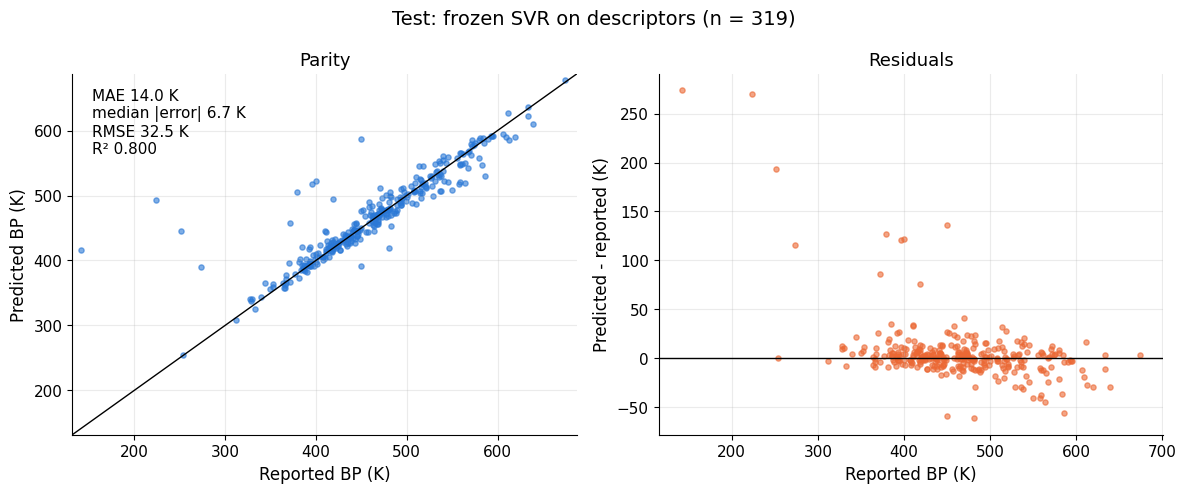

Saved 01_boiling_point/outputs/bp_one_shot_3/figures/fig09_test_parity_residuals.png


PosixPath('/home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_3/figures/fig09_test_parity_residuals.png')

In [33]:
parity_and_residuals(y_te, pred_test, f'Test: frozen {BEST_LABEL}', 'fig09_test_parity_residuals')

### Representative test errors

Code Summary: Lists the three best and four worst test predictions with their nearest training molecule. Reported for understanding only; nothing is tuned after this.


In [34]:
sim_te, nn_te = max_similarity('test')
test_predictions['similarity'] = sim_te
test_predictions['applicability'] = ad_band(sim_te)
test_predictions['nearest_train'] = [train_ids[j] for j in nn_te]
test_predictions['nearest_train_K'] = y_all[IDX['train']][nn_te]
order = test_predictions['error_K'].abs().sort_values().index
display(test_predictions.loc[order[:3]].round(2))
display(test_predictions.loc[order[-4:][::-1]].round(2))
test_ad = test_predictions.groupby('applicability')['error_K'].agg(n='size', MAE_K=lambda e: e.abs().mean())
display(test_ad.reindex(['in-domain', 'borderline', 'out-of-domain']).round(2))
test_predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False)
STAGES.append('test')

,canonical_smiles,reported_BP_K,predicted_BP_K,error_K,similarity,applicability,nearest_train,nearest_train_K
303,OC1CCCCCC1,458.2,458.19,-0.01,0.67,in-domain,OC1CCC1,396.0
32,C=CCc1ccc(O)c(OC)c1,526.4,526.30,-0.10,0.71,in-domain,C=CCc1ccc(OC)c(OC)c1,527.9
192,CCNC1CCCCC1,437.2,437.05,-0.15,0.58,in-domain,CCCCNC1CCCCC1,480.2


,canonical_smiles,reported_BP_K,predicted_BP_K,error_K,similarity,applicability,nearest_train,nearest_train_K
59,CC(C)CC(=O)OC(C)C,141.80,415.79,273.99,0.57,in-domain,CC(C)OC(=O)CCl,423.7
145,CCCCCC(=O)C=CC(C)C,223.50,493.84,270.34,0.48,borderline,CCCCCC(=O)C(C)C,456.0
273,N#CC#N,252.00,445.47,193.47,0.50,in-domain,N#CC#CC#N,349.7
75,CC(OC(C)c1ccccc1)c1ccccc1,450.15,586.37,136.22,0.55,in-domain,CC(c1ccccc1)C(C)c1ccccc1,577.2


,n,MAE_K
applicability,,
in-domain,243,13.08
borderline,73,17.16
out-of-domain,3,14.47


**Did we meet the Step 1 goal? Yes.** On 319 never-seen test molecules the frozen SVR reaches **MAE 14.0 K**, RMSE 32.5 K and R² 0.80. The training-median baseline reaches 56.4 K, 72.8 K and R² ≈ 0. That is a 75% reduction and below the 20 K target. Test MAE is 1.6 K higher than validation. A modest gap is expected, because validation was used to choose the model and settings.

**Why RMSE is so much larger than MAE:** a handful of large misses dominate it. The worst four are isopropyl isovalerate reported at 141.8 K (it is a liquid at room temperature), a C10 enone at 223.5 K, cyanogen (`N#CC#N`, genuinely 252 K, a small, unusual molecule the model overestimates by about 190 K), and an aromatic ether. Half of the test predictions are within **6.7 K** (median absolute error; baseline 47.6 K), so a typical prediction is about twice as good as the MAE suggests.

**Applicability on test:** in-domain MAE 13.1 K (n = 243), borderline 17.2 K (n = 73), out-of-domain 14.5 K (n = 3). The bands are not cleanly ordered and the out-of-domain group is tiny, which confirms that the similarity flag is a coarse warning only.

<h3 style="color:#B05E27;">What we asked / what we decided</h3>

Package the frozen model as one function that accepts SMILES, refuses inputs it cannot handle, and shows how familiar each molecule is. Then prove that a fresh Python process reproduces it.

### Prediction function and saved pipeline

Code Summary: Defines the prediction function, which accepts one SMILES or a list and returns one row per input in order, and saves the frozen pipeline with joblib next to the toolkit module it needs.


In [35]:
def predict_boiling_point(smiles, predictor=None):
    """Predict reported BP (K and degC) for one SMILES or a list, preserving input order.

    Each row has a status: 'ok', 'invalid' (unreadable) or 'unsupported' (salt, ion,
    unseen element or too large). Non-ok rows get no number. The applicability flag
    comes from the highest Tanimoto similarity to a training molecule; it is a warning,
    not a calibrated probability.
    """
    return (predictor or PREDICTOR).predict(smiles)


PIPELINE_PATH = OUT_DIR / 'bp_inference_pipeline.joblib'
joblib.dump(PREDICTOR, PIPELINE_PATH, compress=3)
print(f'Saved {PIPELINE_PATH.relative_to(REPO)} ({PIPELINE_PATH.stat().st_size / 1e6:.2f} MB) '
      f'with module {INFERENCE_MODULE.relative_to(REPO)}')

Saved 01_boiling_point/outputs/bp_one_shot_3/bp_inference_pipeline.joblib (0.19 MB) with module 01_boiling_point/outputs/bp_one_shot_3/bp_inference.py


### Reload in a fresh Python process

Code Summary: Starts a new Python interpreter that only loads the saved files, predicts a fixed list of molecules without retraining, and compares the numbers with this notebook's predictions.


In [36]:
RELOAD_SMILES = ['CCO', 'CCCCC', 'CC(C)(C)C', 'Cc1ccccc1', 'ClC(Cl)Cl', 'C1CC'] + test_ids[:20].tolist()
script = (
    'import sys, joblib\n'
    f'sys.path.insert(0, {str(OUT_DIR)!r})\n'
    'import bp_inference\n'
    f'predictor = joblib.load({str(PIPELINE_PATH)!r})\n'
    f'print(predictor.predict({RELOAD_SMILES!r}).to_json(orient="records"))\n')
proc = subprocess.run([sys.executable, '-c', script], capture_output=True, text=True, cwd=REPO, check=True)
fresh = pd.DataFrame(json.loads(proc.stdout.strip().splitlines()[-1]))
here = predict_boiling_point(RELOAD_SMILES)
RELOAD_MAX_DIFF = float(np.nanmax(np.abs(fresh['predicted_bp_K'].astype(float) - here['predicted_bp_K'])))
# The last 20 inputs are test molecules: the predictor must match the Step 10 numbers too.
RELOAD_OK = bool(RELOAD_MAX_DIFF < 1e-6 and (fresh['status'] == here['status']).all()
                 and np.allclose(fresh['predicted_bp_K'].astype(float).iloc[6:], pred_test[:20], atol=1e-6))
print(f'Fresh process reproduced {len(fresh)} rows; max |difference| = {RELOAD_MAX_DIFF:.2e} K; match: {RELOAD_OK}')

Fresh process reproduced 26 rows; max |difference| = 4.83e-11 K; match: True


### Demonstration on contrasting molecules

Code Summary: Predicts a small alcohol, a linear and a branched isomer, an aromatic, two chlorocarbons, a carboxylic acid and an invalid string, and marks whether each molecule is already in one of the dataset splits.


In [37]:
DEMO = {'ethanol': 'CCO', 'n-pentane': 'CCCCC', 'neopentane (branched isomer)': 'CC(C)(C)C', 'toluene': 'Cc1ccccc1',
        'chloroform': 'ClC(Cl)Cl', 'chlorobenzene': 'Clc1ccccc1', 'acetic acid': 'CC(=O)O', 'invalid ring': 'C1CC'}
# Approximate literature normal boiling points (K), shown for orientation only and never used by the model.
LITERATURE_K = {'ethanol': 351.4, 'n-pentane': 309.2, 'neopentane (branched isomer)': 282.7, 'toluene': 383.8,
                'chloroform': 334.3, 'chlorobenzene': 404.9, 'acetic acid': 391.1}
split_of = dict(zip(clean['canonical_smiles'], clean['split']))
demo = predict_boiling_point(list(DEMO.values()))
demo.insert(0, 'name', list(DEMO))
demo['dataset_split'] = demo['canonical_smiles'].map(split_of).fillna('not in dataset')
demo['literature_K (orientation)'] = demo['name'].map(LITERATURE_K)
display(demo[['name', 'input_smiles', 'status', 'predicted_bp_K', 'predicted_bp_C', 'literature_K (orientation)',
              'applicability', 'max_tanimoto_to_train', 'nearest_train_smiles', 'dataset_split', 'note']].round(1))

,name,input_smiles,status,predicted_bp_K,predicted_bp_C,literature_K (orientation),applicability,max_tanimoto_to_train,nearest_train_smiles,dataset_split,note
0,ethanol,CCO,ok,347.8,74.6,351.4,borderline,0.4,CCC(CC)=C(CC)CC,not in dataset,
1,n-pentane,CCCCC,ok,311.1,37.9,309.2,in-domain,0.7,CCCCCCCCCCCCCCCCC,not in dataset,
2,neopentane (branched isomer),CC(C)(C)C,ok,293.3,20.2,282.7,borderline,0.3,CC(C)(C)CCC(C)(C)C,not in dataset,
3,toluene,Cc1ccccc1,ok,389.1,116.0,383.8,in-domain,0.5,Cc1ccc(CCc2ccccc2)cc1,not in dataset,
4,chloroform,ClC(Cl)Cl,ok,353.4,80.3,334.3,borderline,0.3,ClC(Cl)C(Cl)(Cl)Cl,not in dataset,
5,chlorobenzene,Clc1ccccc1,ok,414.3,141.1,404.9,in-domain,0.6,Clc1ccc(-c2ccccc2)cc1,not in dataset,
6,acetic acid,CC(=O)O,ok,398.9,125.7,391.1,in-domain,0.6,CC(=O)C(=O)O,not in dataset,
7,invalid ring,C1CC,invalid,NaN,NaN,NaN,not scored,NaN,None,not in dataset,RDKit could not parse the SMILES


**Demonstration notes.** None of these molecules is in any split of the dataset, so they are genuinely new to the model. The literature column is approximate orientation only, not evidence of accuracy. The model ranks the pentane isomers correctly (linear pentane above branched neopentane, a shape effect). It predicts ethanol within about 4 K of its literature value despite its small size (H-bonding), and the acid above the alcohol. Chloroform is overestimated by about 19 K and is flagged only *borderline*. Note that the nearest training "neighbours" of small molecules can be quite different molecules (e.g. pentane → heptadecane), which is another reason to read similarity as a hint, not a guarantee.

### Edge cases for the prediction function

Code Summary: Runs the required edge cases through the saved predictor: empty string, invalid SMILES, a salt, a single atom, a stereoisomer pair, a very large molecule, and a mixed list with a duplicate, then checks status, order and finiteness.


In [38]:
big = 'C' * 60
edge_inputs = ['', 'C1CC', '[Na+].[Cl-]', 'C', 'C/C=C/C', 'C/C=C\\C', big, 'CCO', 'not a smiles', 'CCO', 'c1ccccc1O']
edge = predict_boiling_point(edge_inputs)
display(edge[['input_smiles', 'canonical_smiles', 'status', 'predicted_bp_K', 'applicability', 'note']]
        .assign(input_smiles=lambda d: d['input_smiles'].str.slice(0, 24)).round(1))
EDGE_CHECKS = {
    'empty string -> invalid': edge.loc[0, 'status'] == 'invalid',
    'invalid SMILES C1CC -> invalid': edge.loc[1, 'status'] == 'invalid',
    'salt [Na+].[Cl-] -> unsupported': edge.loc[2, 'status'] == 'unsupported',
    'single atom C -> finite prediction': edge.loc[3, 'status'] == 'ok' and np.isfinite(edge.loc[3, 'predicted_bp_K']),
    'stereoisomer pair -> same identity and prediction': (edge.loc[4, 'canonical_smiles'] == edge.loc[5, 'canonical_smiles']
                                                          and edge.loc[4, 'predicted_bp_K'] == edge.loc[5, 'predicted_bp_K']
                                                          and 'stereochemistry removed' in edge.loc[4, 'note']),
    'very large molecule -> unsupported': edge.loc[6, 'status'] == 'unsupported',
    'mixed list keeps input order': edge['input_smiles'].tolist() == edge_inputs,
    'duplicate inputs -> identical rows': edge.loc[7, 'predicted_bp_K'] == edge.loc[9, 'predicted_bp_K'],
    'non-ok rows carry no number': edge.loc[edge['status'] != 'ok', 'predicted_bp_K'].isna().all(),
    'every ok row is finite': np.isfinite(edge.loc[edge['status'] == 'ok', 'predicted_bp_K']).all(),
}
for name, ok in EDGE_CHECKS.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
STAGES.append('inference')

,input_smiles,canonical_smiles,status,predicted_bp_K,applicability,note
0,,None,invalid,NaN,not scored,empty or missing SMILES
1,C1CC,None,invalid,NaN,not scored,RDKit could not parse the SMILES
2,[Na+].[Cl-],[Cl-].[Na+],unsupported,NaN,not scored,multi-component entry (salt or mixture)
3,C,C,ok,198.7,out-of-domain,
4,C/C=C/C,CC=CC,ok,276.9,in-domain,stereochemistry removed
5,C/C=C\C,CC=CC,ok,276.9,in-domain,stereochemistry removed
6,CCCCCCCCCCCCCCCCCCCCCCCC,CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC...,unsupported,NaN,not scored,60 heavy atoms exceeds the supported maximum of 25
7,CCO,CCO,ok,347.8,borderline,
8,not a smiles,None,invalid,NaN,not scored,RDKit could not parse the SMILES
9,CCO,CCO,ok,347.8,borderline,


PASS  empty string -> invalid
PASS  invalid SMILES C1CC -> invalid
PASS  salt [Na+].[Cl-] -> unsupported
PASS  single atom C -> finite prediction
PASS  stereoisomer pair -> same identity and prediction
PASS  very large molecule -> unsupported
PASS  mixed list keeps input order
PASS  duplicate inputs -> identical rows
PASS  non-ok rows carry no number
PASS  every ok row is finite


<h2 style="color:#1D4E89;">Verification</h2>

Every item in the prompt's TESTS section, asserted against this run. The notebook stops here if any item fails.

### Verification checklist

Code Summary: Asserts each required property of this run and prints PASS or FAIL per item: one checksummed source in kelvin, SMILES-only features, disjoint splits, training-only fitting, sealed test set, aligned predictions, edge cases, fresh-process reload, stage order and the repository fast checks.


In [39]:
CHECKS = {}


def check(name, condition):
    CHECKS[name] = bool(condition)
    print(f"{'PASS' if condition else 'FAIL'}  {name}")


# 1. One source, checksum, kelvin
check('1. exactly one data source, checksum recorded, BP units confirmed as kelvin',
      DATA_PATH in (PREFERRED_DATA, FALLBACK_DATA) and len(DATA_SHA256) == 64
      and sha256_file(DATA_PATH) == DATA_SHA256 and BP_UNITS == 'K')

# 2. SMILES-only features: no stored column, and features recompute exactly from SMILES
sample = np.random.default_rng(SEED).choice(len(clean), 25, replace=False)
recomputed = bp_inference.featurize([Chem.MolFromSmiles(s) for s in clean['canonical_smiles'].iloc[sample]],
                                    FEATURE_SETS[FINAL['feature_set']], MORGAN_RADIUS, MORGAN_COUNT_BITS)
check('2. no stored measurement is a model input; features recompute from SMILES',
      not BANNED_INPUTS & set(FEATURE_SETS[FINAL['feature_set']])
      and np.allclose(recomputed.to_numpy(float), X_ALL.iloc[sample][FEATURE_SETS[FINAL['feature_set']]].to_numpy(float), equal_nan=True))

# 3. Disjoint identities and counts
saved_split = pd.read_csv(OUT_DIR / 'split_assignments.csv')
check('3. identities disjoint across splits; counts sum to eligible molecules',
      saved_split['canonical_smiles'].is_unique and len(saved_split) == len(clean)
      and sum(len(v) for v in IDX.values()) == len(clean)
      and not (SPLIT_SETS['train'] & SPLIT_SETS['validation'] or SPLIT_SETS['train'] & SPLIT_SETS['test']
               or SPLIT_SETS['validation'] & SPLIT_SETS['test']))

# 4. Preprocessing fitted on training rows only (inspect the fitted scaler/imputer)
X_tr_final, _ = split_xy(FINAL['feature_set'], 'train')
fitted = FINAL['model']
inner = fitted.regressor_ if hasattr(fitted, 'regressor_') else fitted
if hasattr(inner, 'named_steps'):
    scaler, imputer = inner.named_steps['standardscaler'], inner.named_steps['simpleimputer']
    train_only = (scaler.n_samples_seen_ == len(IDX['train'])
                  and np.allclose(scaler.mean_, np.nanmean(imputer.transform(X_tr_final), axis=0))
                  and np.allclose(imputer.statistics_, np.nanmedian(X_tr_final, axis=0)))
    if hasattr(fitted, 'transformer_'):
        train_only = train_only and np.isclose(fitted.transformer_.mean_[0], y_all[IDX['train']].mean())
else:
    train_only = getattr(inner, 'n_features_in_', None) == X_tr_final.shape[1]
check('4. scalers, imputers and target scaling fitted on training rows only', train_only)

# 5. No test predictions before the freeze
exp_splits = set()
for folder in sorted(p for p in EXP_DIR.glob('experiment_[0-9]*') if p.is_dir()):
    exp_splits |= set(pd.read_csv(folder / 'predictions.csv')['split'])
check('5. no test predictions or metrics before the Step 9 freeze',
      FROZEN_AT <= TEST_OPENED_AT and exp_splits == {'train', 'validation'}
      and not any('test' in c for c in pd.read_csv(EXP_DIR / 'experiment_summary.csv').columns))

# 6. Alignment and finiteness
saved_test = pd.read_csv(OUT_DIR / 'test_predictions.csv')
check('6. prediction rows align with identities; every valid input has a finite prediction',
      saved_test['canonical_smiles'].tolist() == test_ids.tolist()
      and np.allclose(saved_test['reported_BP_K'], y_all[IDX['test']])
      and np.isfinite(saved_test['predicted_BP_K']).all() and np.isfinite(FINAL['pred_val']).all())

# 7. Edge cases
check('7. prediction function handles all required edge cases', all(EDGE_CHECKS.values()))

# 8. Fresh-process reload
check('8. saved pipeline reloads in a fresh process and reproduces predictions', RELOAD_OK)

# 9. Top-to-bottom execution in this kernel
EXPECTED_STAGES = ['load', 'audit', 'split', 'examine', 'carpentry', 'features', 'baseline', 'tracker',
                   'experiments', 'analysis', 'freeze', 'test', 'inference']
check('9. every stage ran once, in order, in this kernel (saved-output check: see final report)',
      STAGES == EXPECTED_STAGES)

# 10. Repository fast checks
nb_check = subprocess.run([sys.executable, 'scripts/ci/validate_notebooks.py'], cwd=REPO, capture_output=True, text=True)
check('10a. scripts/ci/validate_notebooks.py', nb_check.returncode == 0)
unit = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests'], cwd=REPO, capture_output=True, text=True)
failed = sorted({line.split('(')[1].split(')')[0] for line in unit.stderr.splitlines() if line.startswith(('FAIL:', 'ERROR:'))})
mine = [line for line in unit.stderr.splitlines() if 'prompt_test' in line or OUTPUT_NAME in line]
check('10b. unit tests: no failure involves this notebook or its outputs', not mine)
print(f'      (unittest return code {unit.returncode}; {len(failed)} failing test cases, all pre-existing '
      f'and unrelated if 10b passed: {", ".join(failed[:4])}{" ..." if len(failed) > 4 else ""})')
VERIFICATION_PASSED = all(CHECKS.values())
assert VERIFICATION_PASSED, 'A verification item failed; fix it before trusting this notebook.'
print('\nAll verification items passed.')

PASS  1. exactly one data source, checksum recorded, BP units confirmed as kelvin
PASS  2. no stored measurement is a model input; features recompute from SMILES
PASS  3. identities disjoint across splits; counts sum to eligible molecules
PASS  4. scalers, imputers and target scaling fitted on training rows only


PASS  5. no test predictions or metrics before the Step 9 freeze
PASS  6. prediction rows align with identities; every valid input has a finite prediction
PASS  7. prediction function handles all required edge cases
PASS  8. saved pipeline reloads in a fresh process and reproduces predictions
PASS  9. every stage ran once, in order, in this kernel (saved-output check: see final report)


PASS  10a. scripts/ci/validate_notebooks.py


PASS  10b. unit tests: no failure involves this notebook or its outputs
      (unittest return code 1; 20 failing test cases, all pre-existing and unrelated if 10b passed: test_bp_workbook.BoilingPointWorkbookTests.test_documented_template_and_prompt_destinations_match_the_module_layout, test_bp_workbook.BoilingPointWorkbookTests.test_main_path_and_optional_reference_library, test_bp_workbook.BoilingPointWorkbookTests.test_moved_references_resolve_shared_data_and_outputs_from_all_supported_folders, test_bp_workbook.BoilingPointWorkbookTests.test_notebook_markdown_links_still_point_to_existing_local_files ...)

All verification items passed.


<h2 style="color:#1D4E89;">Results, summary and reproducibility</h2>

### Final results table and run manifest

Code Summary: Prints the baseline-versus-model table for validation and test, then writes the run manifest and artifact README with the source checksum, policies, seeds, package versions, selected configuration, runtime and exact reproduction commands.


In [40]:
results = (final_metrics[final_metrics['split'].isin(['validation', 'test'])]
           .pivot(index='model', columns='split', values=['MAE_K', 'MedAE_K', 'RMSE_K', 'R2']).round(3))
display(results)
RUNTIME_MIN = (time.perf_counter() - RUN_START) / 60
packages = {'python': sys.version.split()[0]}
for name, mod in [('numpy', 'numpy'), ('pandas', 'pandas'), ('scikit-learn', 'sklearn'), ('rdkit', 'rdkit'),
                  ('matplotlib', 'matplotlib'), ('joblib', 'joblib')]:
    packages[name] = importlib.import_module(mod).__version__
REPRO = ['uv run --locked jupyter nbconvert --to notebook --execute --inplace ' + NOTEBOOK_REL,
         'uv run --locked python scripts/ci/validate_notebooks.py',
         'uv run --locked python -m unittest discover -s tests -v']
manifest = {
    'notebook': NOTEBOOK_REL, 'started_utc': RUN_STARTED_UTC, 'finished_utc': utc_now(),
    'runtime_minutes_through_this_cell': round(RUNTIME_MIN, 2), 'runtime_budget_minutes': RUNTIME_BUDGET_MIN,
    'source': {'path': DATA_REL, 'sha256': DATA_SHA256, 'rows': int(len(raw)),
               'preferred_nist_acquisition_present': PREFERRED_DATA.exists()},
    'units': {'BP': 'K', 'evidence': 'module README + NIST-origin structures + N2/O2/CO reference values',
              'pressure': 'not recorded; target is reported BP, not verified normal BP'},
    'policies': FROZEN_CONFIG['cleaning_policy'], 'seed': SEED, 'split_fractions': SPLIT_FRACTIONS,
    'split_counts': {s: int(len(v)) for s, v in IDX.items()}, 'eligible_molecules': int(len(clean)),
    'selected_configuration': FROZEN_CONFIG, 'test_opened_utc': TEST_OPENED_AT,
    'test_metrics': final_metrics.query("split == 'test'").to_dict('records'), 'success_criterion_met': SUCCESS,
    'verification': CHECKS, 'package_versions': packages, 'reproduce': REPRO,
}
(OUT_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str) + '\n')
ARTIFACTS = {
    'run_owner.json': 'Marks this folder as owned by the P3 notebook (prevents other runs overwriting it).',
    'bp_inference.py': 'Toolkit module written by the notebook; needed to load the saved pipeline.',
    'cleaning_audit.csv': 'One row per source row: original and canonical SMILES, BP, action and reason.',
    'clean_working_table.csv': 'Unique eligible molecules with median BP (K), report counts and split.',
    'split_assignments.csv': 'Frozen train/validation/test assignment of every canonical identity (seed 42).',
    'feature_spec.json': 'Descriptor groups, fingerprint settings and excluded stored columns.',
    'experiments/': 'Numbered experiment folders (metadata.json, predictions.csv, training_history.csv) and experiment_summary.csv. Train/validation only.',
    'figures/': 'Slide-ready PNG figures referenced in the notebook.',
    'frozen_config.json': 'Selected pipeline and settings, frozen before the test set was opened.',
    'final_metrics.csv': 'Baseline and selected model metrics on train, validation and test.',
    'test_predictions.csv': 'Test molecules with reported and predicted BP, similarity and nearest training molecule.',
    'bp_inference_pipeline.joblib': 'Saved predictor; load with joblib after adding this folder to sys.path.',
    'run_manifest.json': 'Source checksum, units, policies, seeds, versions, configuration, runtime and commands.',
}
readme = [f'# Artifacts of `{Path(NOTEBOOK_REL).name}`', '',
          f'Generated {manifest["finished_utc"]} from `{DATA_REL}` (SHA-256 `{DATA_SHA256[:16]}...`). '
          'BP is in kelvin; pressure is not recorded, so the target is the reported boiling point.', '',
          '| Artifact | Contents |', '|---|---|', *[f'| `{k}` | {v} |' for k, v in ARTIFACTS.items()], '',
          '## Reproduce', '', 'From the repository root:', '', '```bash', *REPRO, '```', '',
          '## Use the saved model', '', '```python', 'import sys, joblib',
          f"sys.path.insert(0, '{OUT_DIR.relative_to(REPO).as_posix()}')",
          'import bp_inference',
          f"predictor = joblib.load('{PIPELINE_PATH.relative_to(REPO).as_posix()}')",
          "print(predictor.predict(['CCO', 'Cc1ccccc1']))", '```', '']
(OUT_DIR / 'README.md').write_text('\n'.join(readme))
missing = [k for k in ARTIFACTS if not (OUT_DIR / k.rstrip('/')).exists()]
assert not missing, missing
size_mb = sum(p.stat().st_size for p in OUT_DIR.rglob('*') if p.is_file()) / 1e6
print(f'Runtime through this cell: {RUNTIME_MIN:.1f} min (budget {RUNTIME_BUDGET_MIN} min); artifacts: {size_mb:.1f} MB')
print(f'Wrote {(OUT_DIR / "run_manifest.json").relative_to(REPO)} and {(OUT_DIR / "README.md").relative_to(REPO)}')

MAE_K            MedAE_K             RMSE_K                R2           
split              test validation    test validation    test validation   test validation
model                                                                                     
median baseline  56.409     56.146  47.550     44.500  72.766     74.358 -0.004     -0.005
selected model   14.025     12.426   6.677      5.768  32.461     29.771  0.800      0.839

Runtime through this cell: 2.4 min (budget 15 min); artifacts: 5.8 MB
Wrote 01_boiling_point/outputs/bp_one_shot_3/run_manifest.json and 01_boiling_point/outputs/bp_one_shot_3/README.md


### Plain-language summary

We taught a computer to estimate a molecule's reported boiling point from its SMILES string alone. The model uses about 35 chemistry-motivated numbers such as size, polarity and hydrogen bonding. On 319 molecules it never saw, its average error is about 14 K, and half of its predictions are within about 7 K. Always guessing the average would be off by about 56 K. A few of its biggest misses look like problems in the reference data rather than the model. It also shows how similar each new molecule is to what it learned from, but that warning is rough and is not a guarantee.

### Limitations

- **Pressure is unknown.** The labels are *reported* boiling points. Several obvious mismatches look like reduced-pressure or mis-assigned values. They remain in the training and test data, so they inflate the errors and may bias the model slightly low for long-chain esters and acids.
- **Random split.** It estimates performance for chemistry similar to the training set. Scaffold-novel or much larger molecules are likely to do worse, and the applicability flag is only a coarse warning.
- **Narrow chemistry.** Only C, H, N, O, S and Cl occur in training, and the largest molecule has 20 heavy atoms. Other elements are rejected, and molecules over 25 heavy atoms are refused.
- **Stereochemistry is ignored.** Stereoisomers get identical predictions, and isomer groups with conflicting labels were excluded.
- **No calibrated uncertainty.** Similarity and model disagreement are warnings, not probabilities or intervals.
- **Single holdout.** One validation/test split of about 320 molecules each; differences under about 1 K between models are not meaningful.

### Refinement log (Self-Refine)

**Round 1, after the first complete run.** Reviewed as a skeptical attendee and as a peer reviewer.
1. *Verification bug:* the experiment-folder check also matched `experiment_summary.csv`. Fixed the pattern to numbered folders only.
2. *Figure readability:* the parity and residual titles overlapped, and the comparison chart's legend covered the baseline bar and used raw run names. We moved the model name into a figure title, shortened the bar labels and moved the legend.
3. *Honesty about outliers:* RMSE and MAE are driven by a few suspect labels, so median absolute error was added to every metric table and plot.
4. *Readable outputs:* tuned settings printed as `np.float64(...)`; they are now plain numbers in the printout and in JSON.
5. *Repository conventions:* the unit tests require every code notebook's teaching notes to be registered in `scripts/prepare_notebook_presentation.py`. The notebook was registered, and its notes are now generated in exactly the catalog's format.

**Round 2, after rerunning from a fresh kernel.** We re-read every output against the narrative. The rerun reproduced every model number exactly; only timings differed. Each quoted number was checked against it. The narrative was missing the new median-error figures (6.7 K test, 5.8 K validation), so they were added to the Step 10 conclusion and the summary. Wording that over-read small groups (out-of-domain n = 8, sulfur n = 18) was softened. No further code changes were needed. Stopped after two rounds as planned.

### Next experiments (ranked)

1. **Label-quality audit against pressure metadata (data).** Re-acquire these compounds with notebook 00, which keeps NIST's per-measurement notes. Flag reduced-pressure entries, then compare *training* on clean labels vs all labels, always evaluating on the same frozen test molecules with their original labels reported alongside. *Expected benefit:* a large RMSE drop and a more honest picture of model error. *Fair test:* same split, same model, and only the training labels change.
2. **Scaffold or cluster split as a second evaluation (evaluation).** Re-evaluate the frozen recipe on a Butina-cluster split (Tanimoto 0.4) to estimate performance on unfamiliar chemistry. *Expected benefit:* a realistic error for new chemical families, and a test of whether the applicability flag works when out-of-domain molecules are common. *Fair test:* report it as a separate estimate; never choose between splits by score.
3. **Chemprop graph network on the same split (model/representation).** Use the `examples/` reference as a template, with early stopping on the frozen validation set. *Expected benefit:* learned substructure features that may help long chains and rare functional groups. *Fair test:* compare against the frozen SVR's validation MAE with the same bootstrap and 1 K rule before any test evaluation, and keep within the runtime budget (CPU, about 5 min).